# Phase 13 — KUB Predicted ROI Proposal / Localizer Development

GT-free proposal generation from frozen UNet++ global probability maps. GT is used only after proposal generation for localization evaluation. No segmentation/refiner training, Oracle proposal generation, TEST access, or external-data access.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd().resolve();ROOT=ROOT.parent if ROOT.name=='notebooks' else ROOT
T=ROOT/'reports/tables';F=ROOT/'reports/figures/phase13_predicted_roi';Q=ROOT/'reports/qualitative/phase13_predicted_roi'
search=pd.read_csv(T/'phase13_predicted_roi_search.csv');selected=pd.read_csv(T/'phase13_predicted_roi_selected_config.csv');components=pd.read_csv(T/'phase13_predicted_roi_per_component.csv');images=pd.read_csv(T/'phase13_predicted_roi_per_image.csv')
assert len(search)==324 and len(components)==156 and len(images)==106
print('Governance PASS: VAL FULL_FIELD only; frozen UNet++; TEST NOT ACCESSED; no training')

Governance PASS: VAL FULL_FIELD only; frozen UNet++; TEST NOT ACCESSED; no training


## Phase-12 motivation and Oracle/deployable distinction

Oracle25 used GT localization and demonstrated resolution headroom. Phase 13 does not use GT to generate boxes: it thresholds frozen coarse probabilities, labels predicted components, scores by maximum component probability, applies predicted-box NMS and Top-K, and expands predicted boxes. Oracle availability is 100% by definition and is not deployment performance.

## Predeclared search grid and frozen selection rule

In [2]:
print('Thresholds:',sorted(search.proposal_threshold.unique()))
print('Margins:',sorted(search.margin.unique()))
print('Top-K:',sorted(search.top_k.unique()))
print('NMS:',sorted(search.nms_iou.unique()))
display(selected)

Thresholds: [np.float64(0.2), np.float64(0.25), np.float64(0.3), np.float64(0.35), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.55), np.float64(0.6)]
Margins: [np.float64(0.05), np.float64(0.1), np.float64(0.15)]
Top-K: [np.int64(1), np.int64(2), np.int64(3), np.int64(5)]
NMS: [np.float64(0.3), np.float64(0.5), np.float64(0.7)]


,proposal_threshold,margin,top_k,nms_iou,overall_recall90,tiny_recall90,small_recall90,medium_recall90,large_recall90,overall_recall50,...,median_component_coverage,mean_proposals_per_image,median_proposals_per_image,zero_proposal_images,mean_total_roi_area_fraction,median_total_roi_area_fraction,mean_maximum_roi_area_fraction,unmatched_proposals,mean_unmatched_proposals_per_image,selection_rule
0,0.5,0.15,3,0.3,0.74359,0.684932,0.862069,0.777778,0.722222,0.794872,...,1.0,1.556604,1.0,7,0.003091,0.000634,0.002342,36,0.339623,"lexicographic: max recall90, max TINY recall90..."


## Recall and proposal efficiency trade-offs

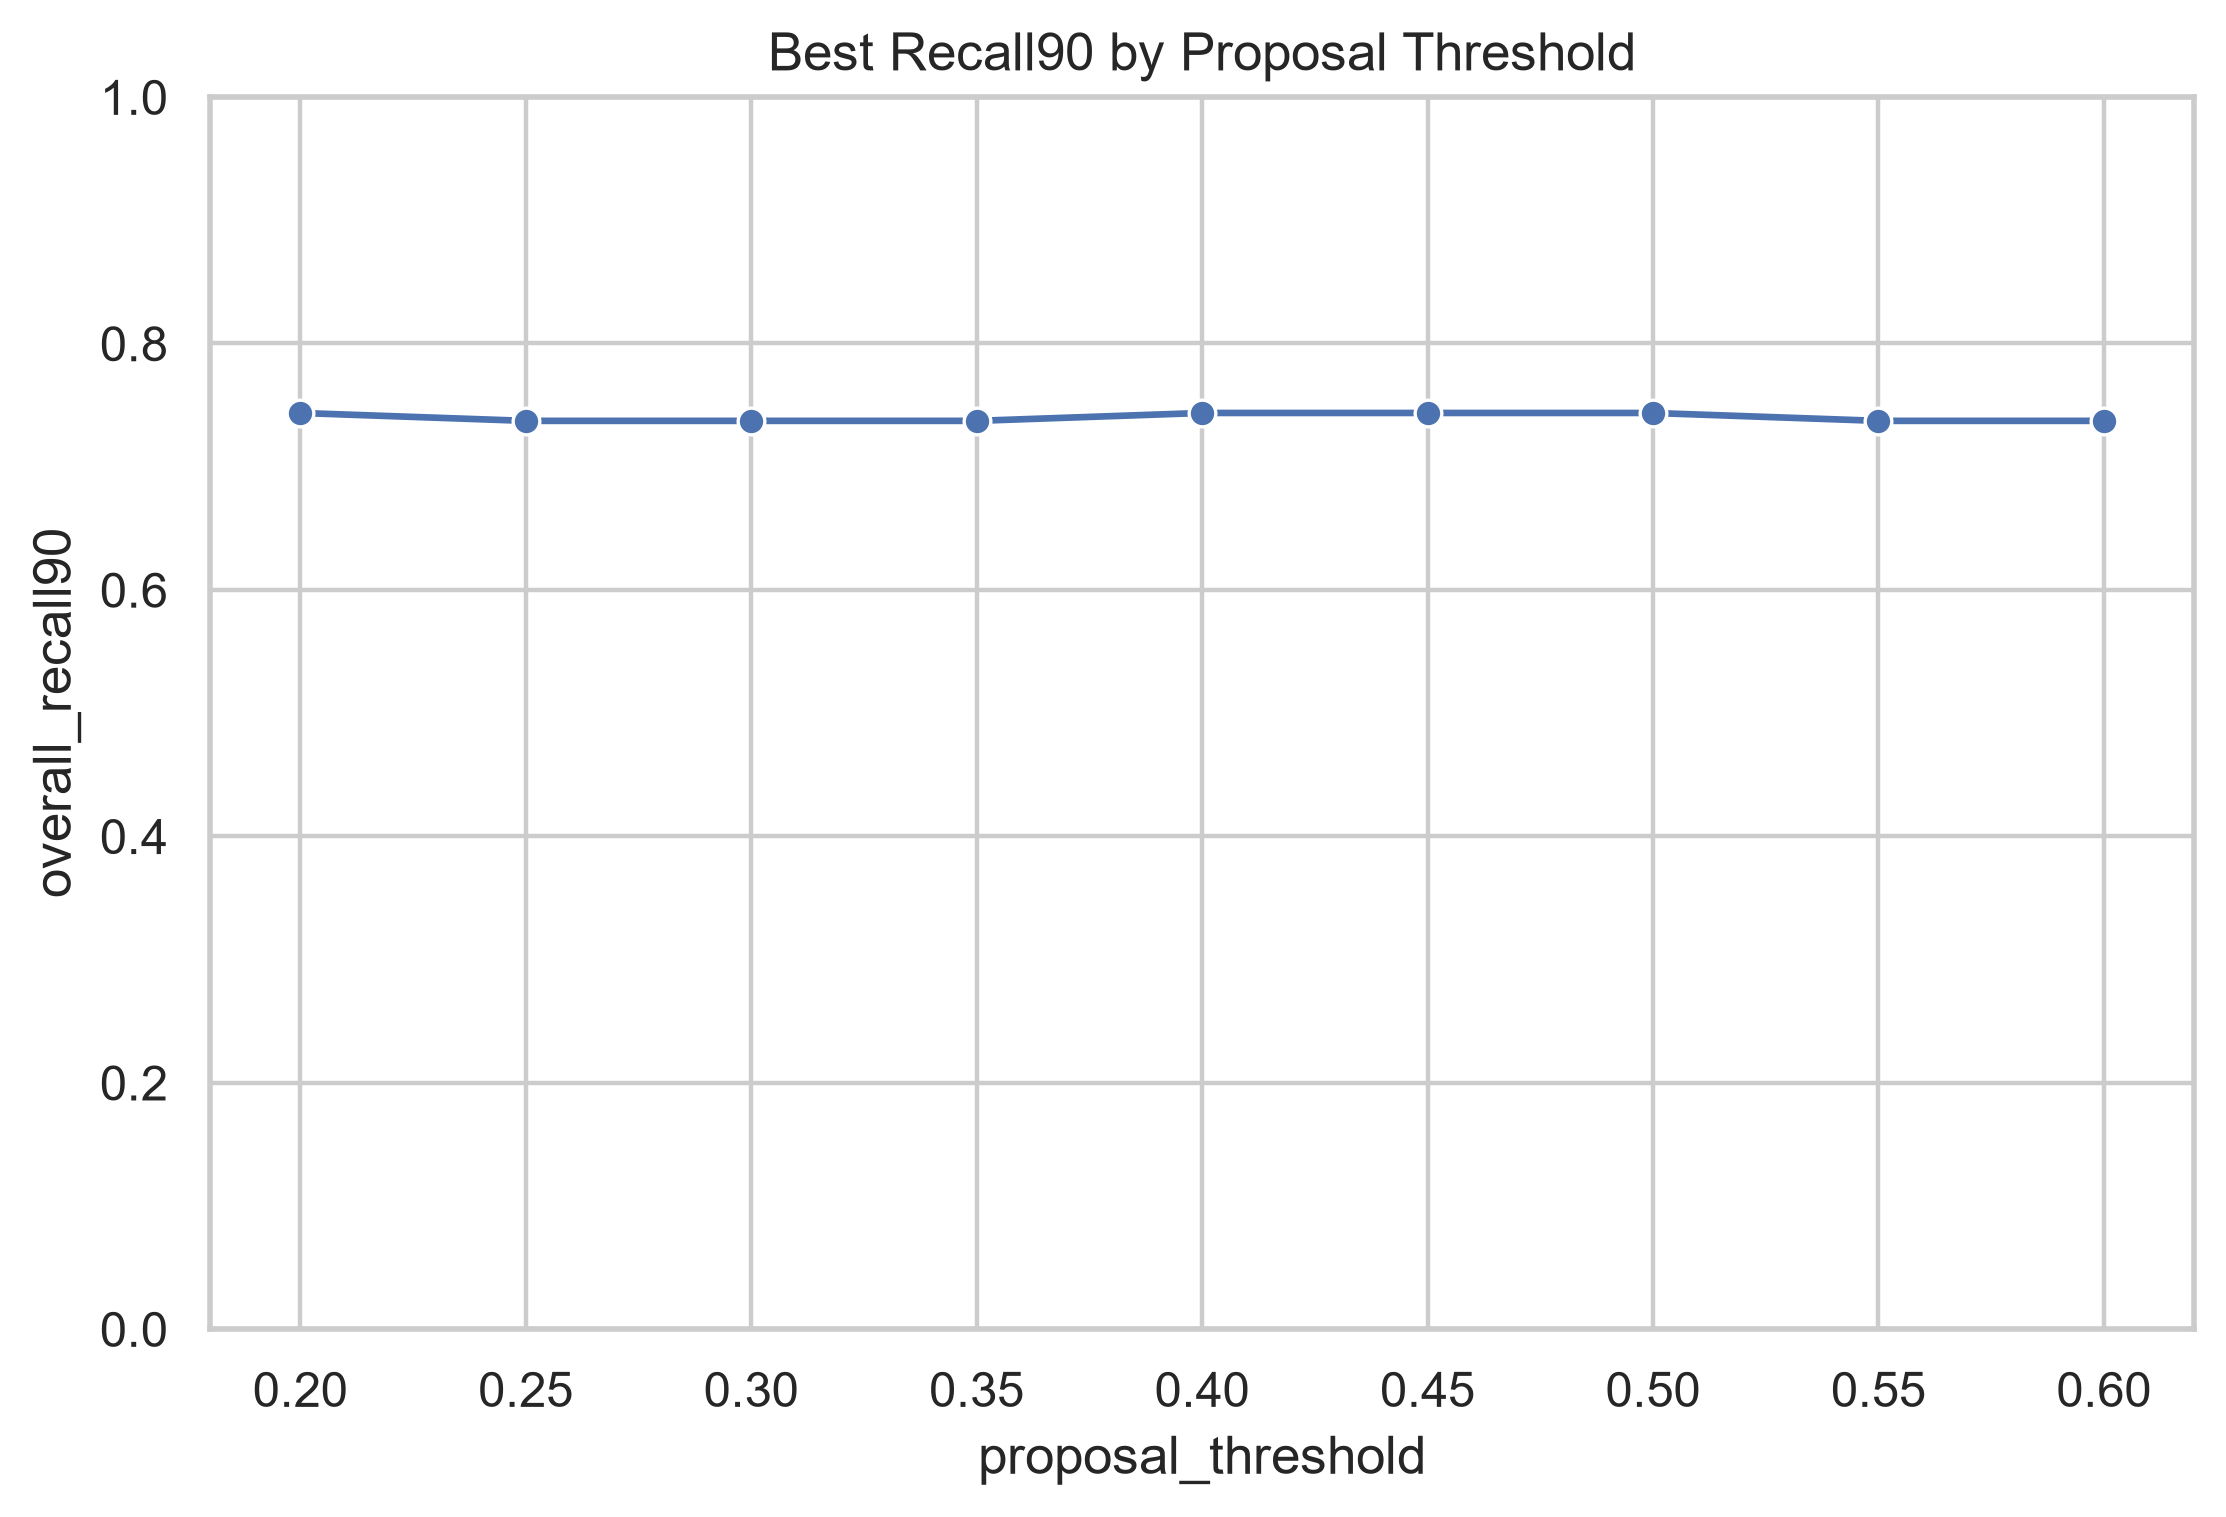

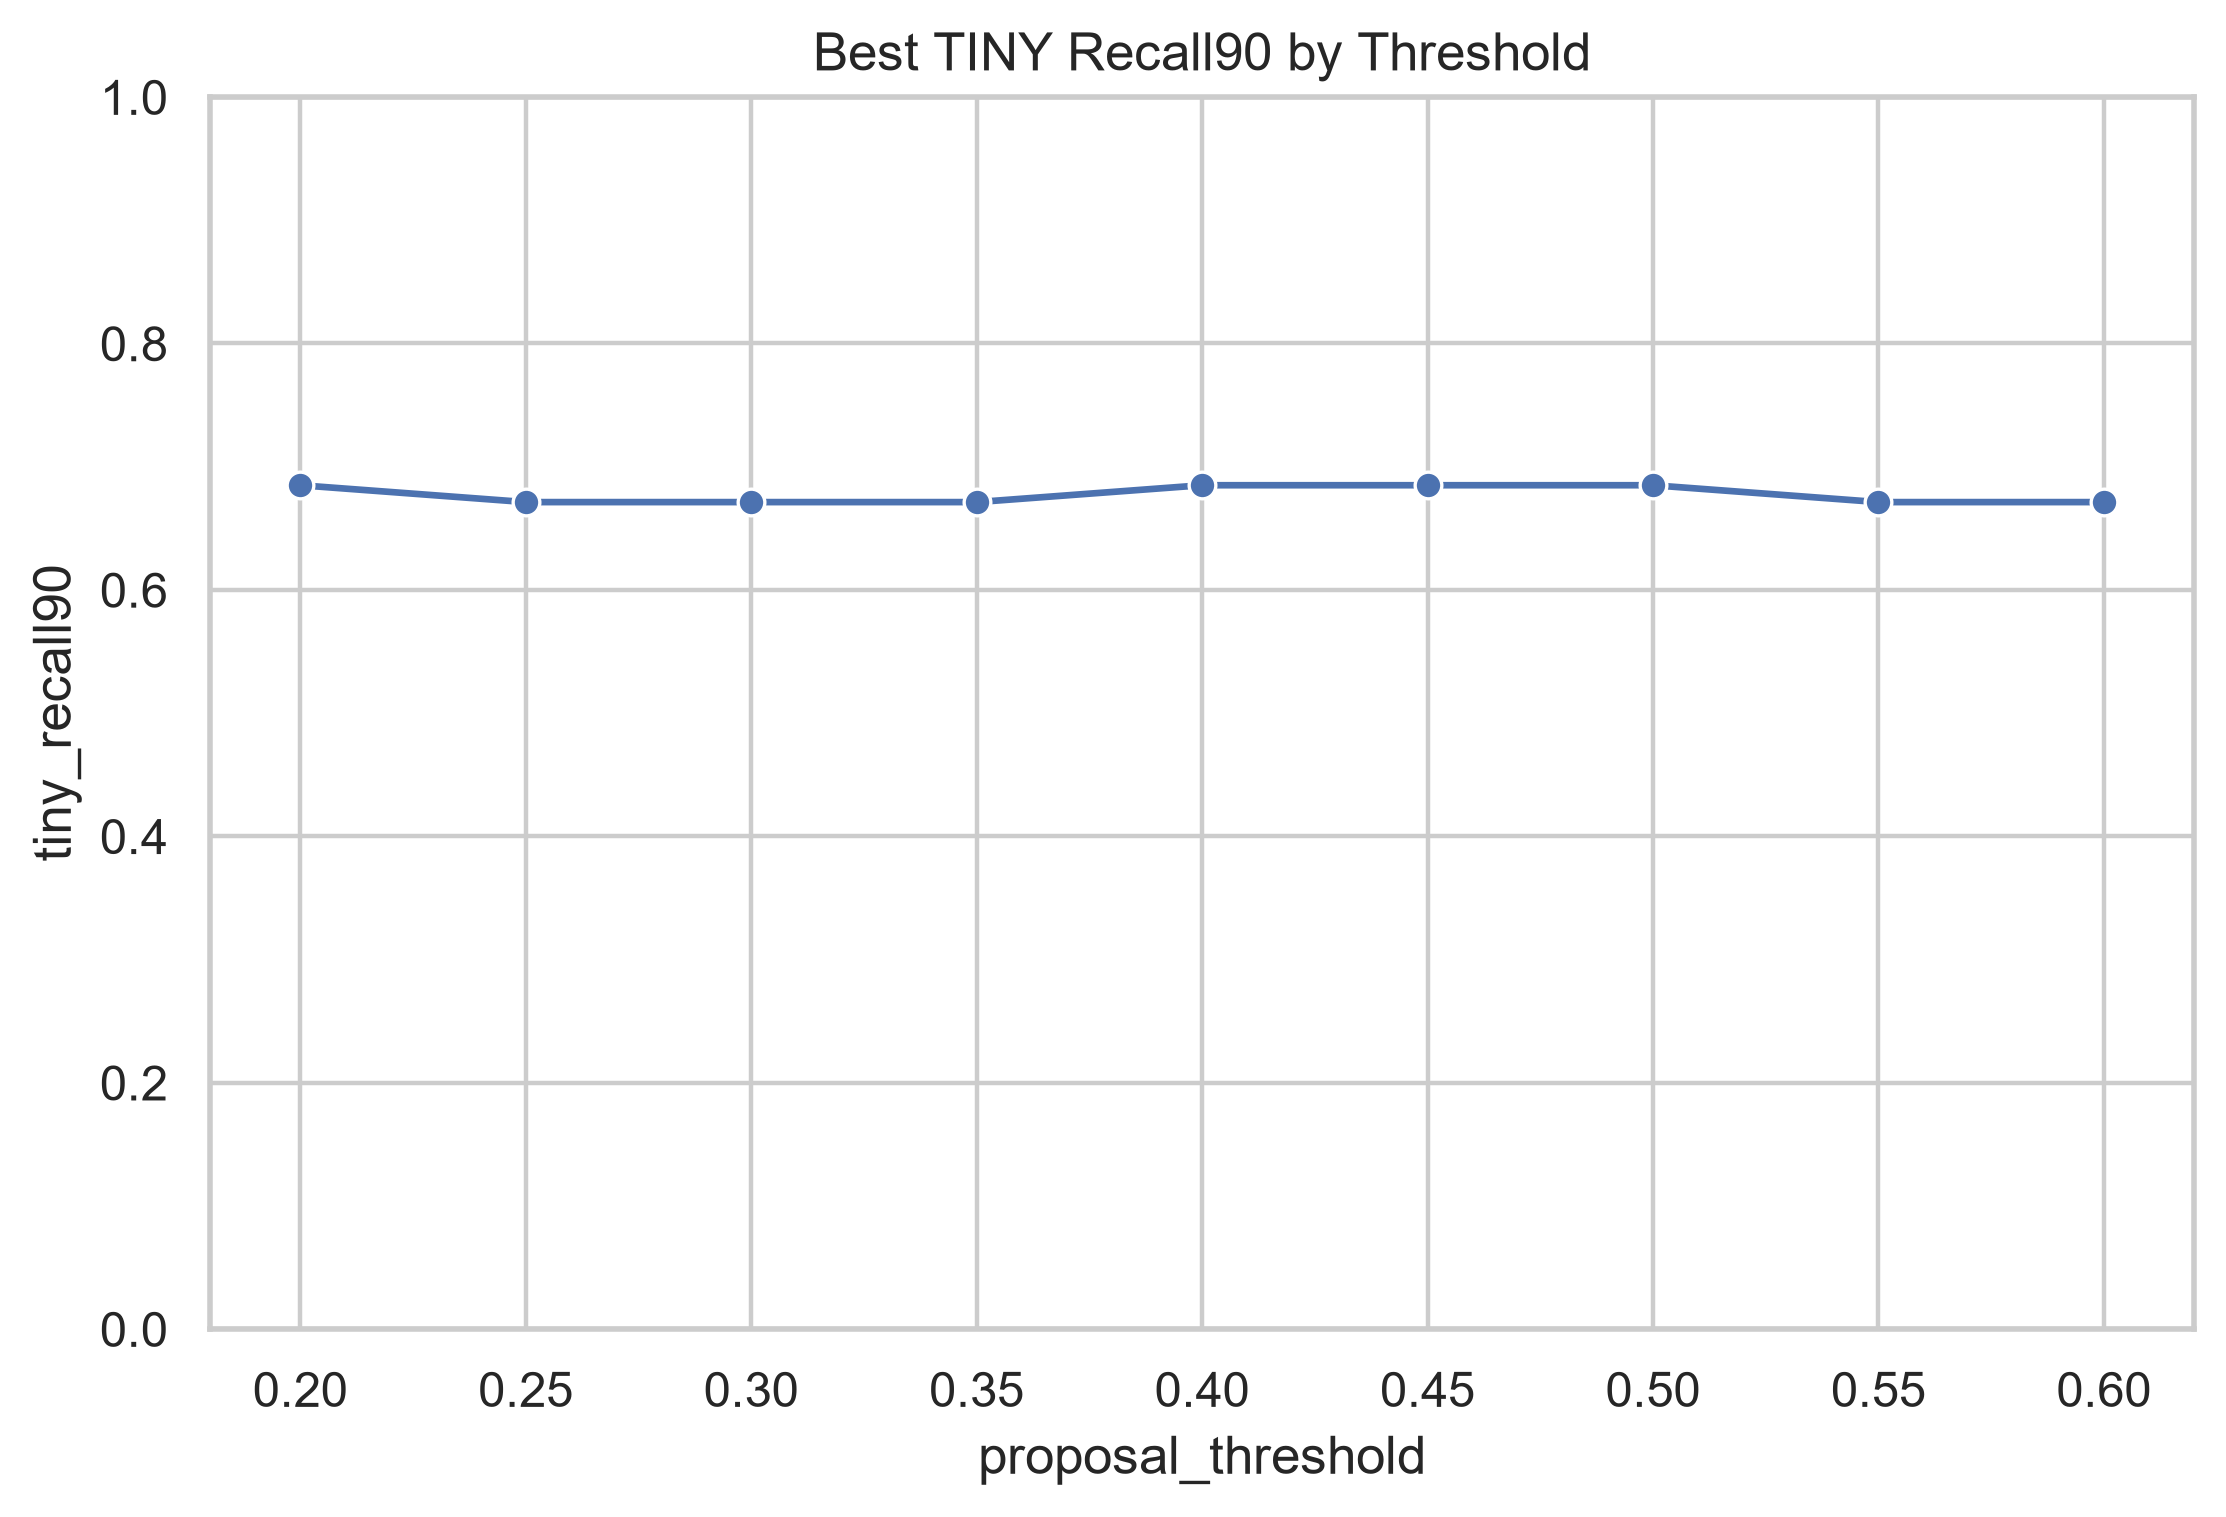

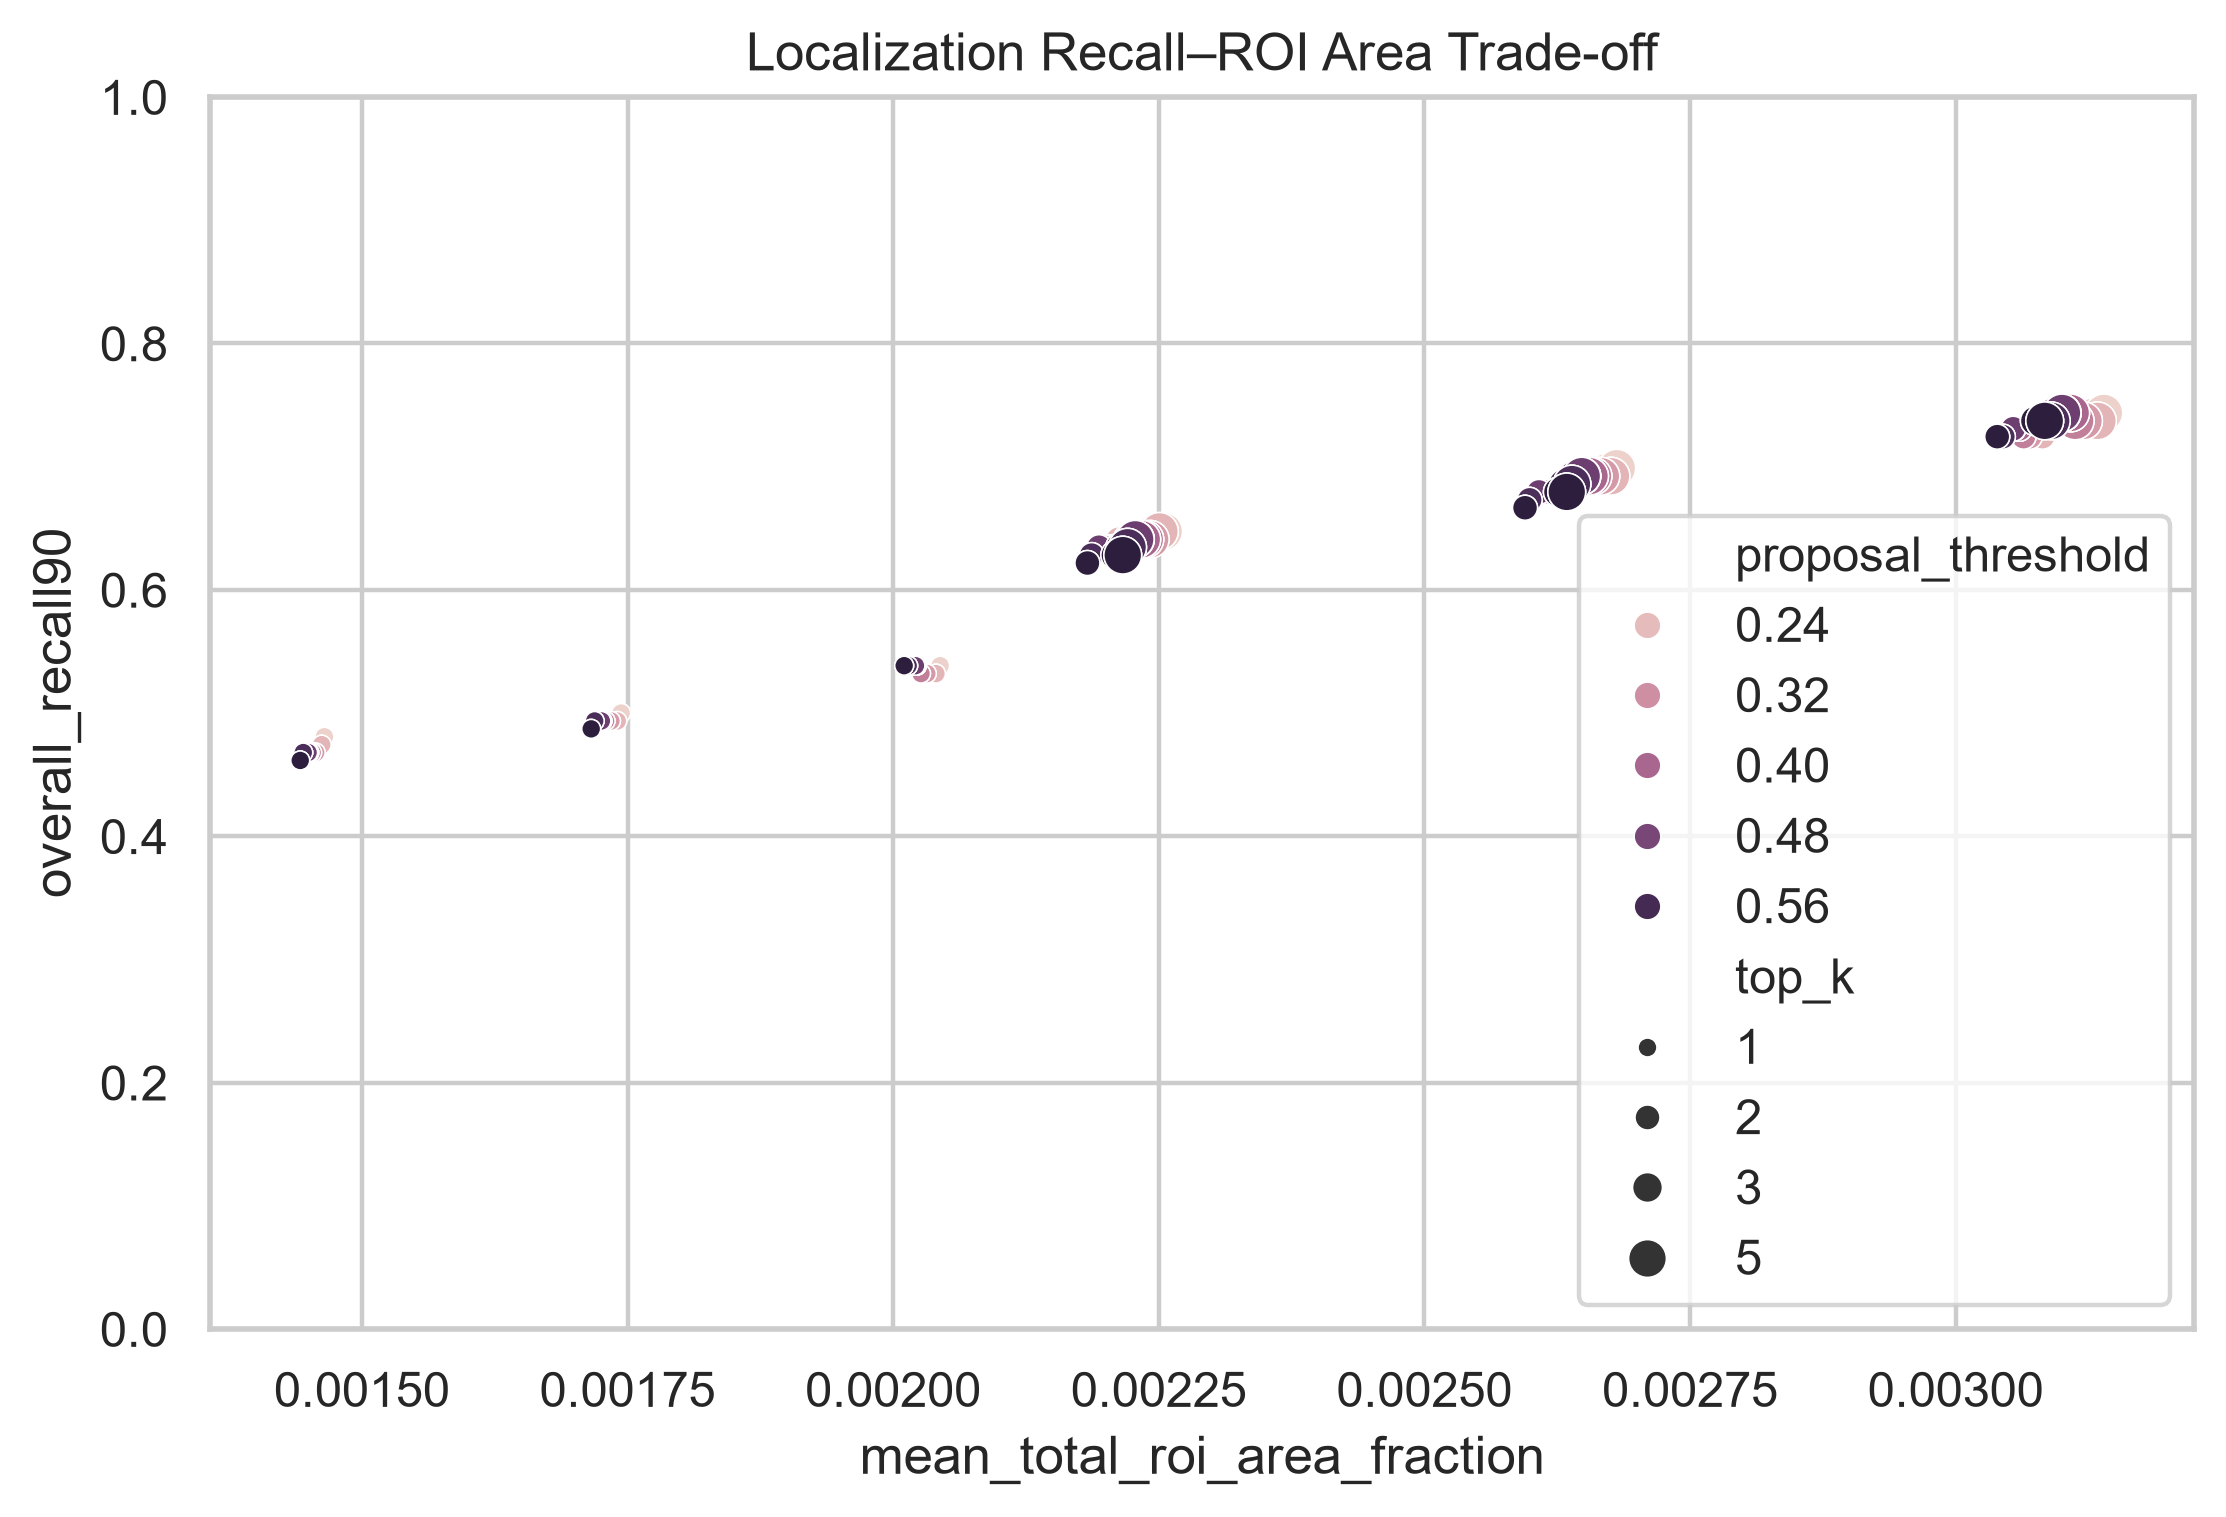

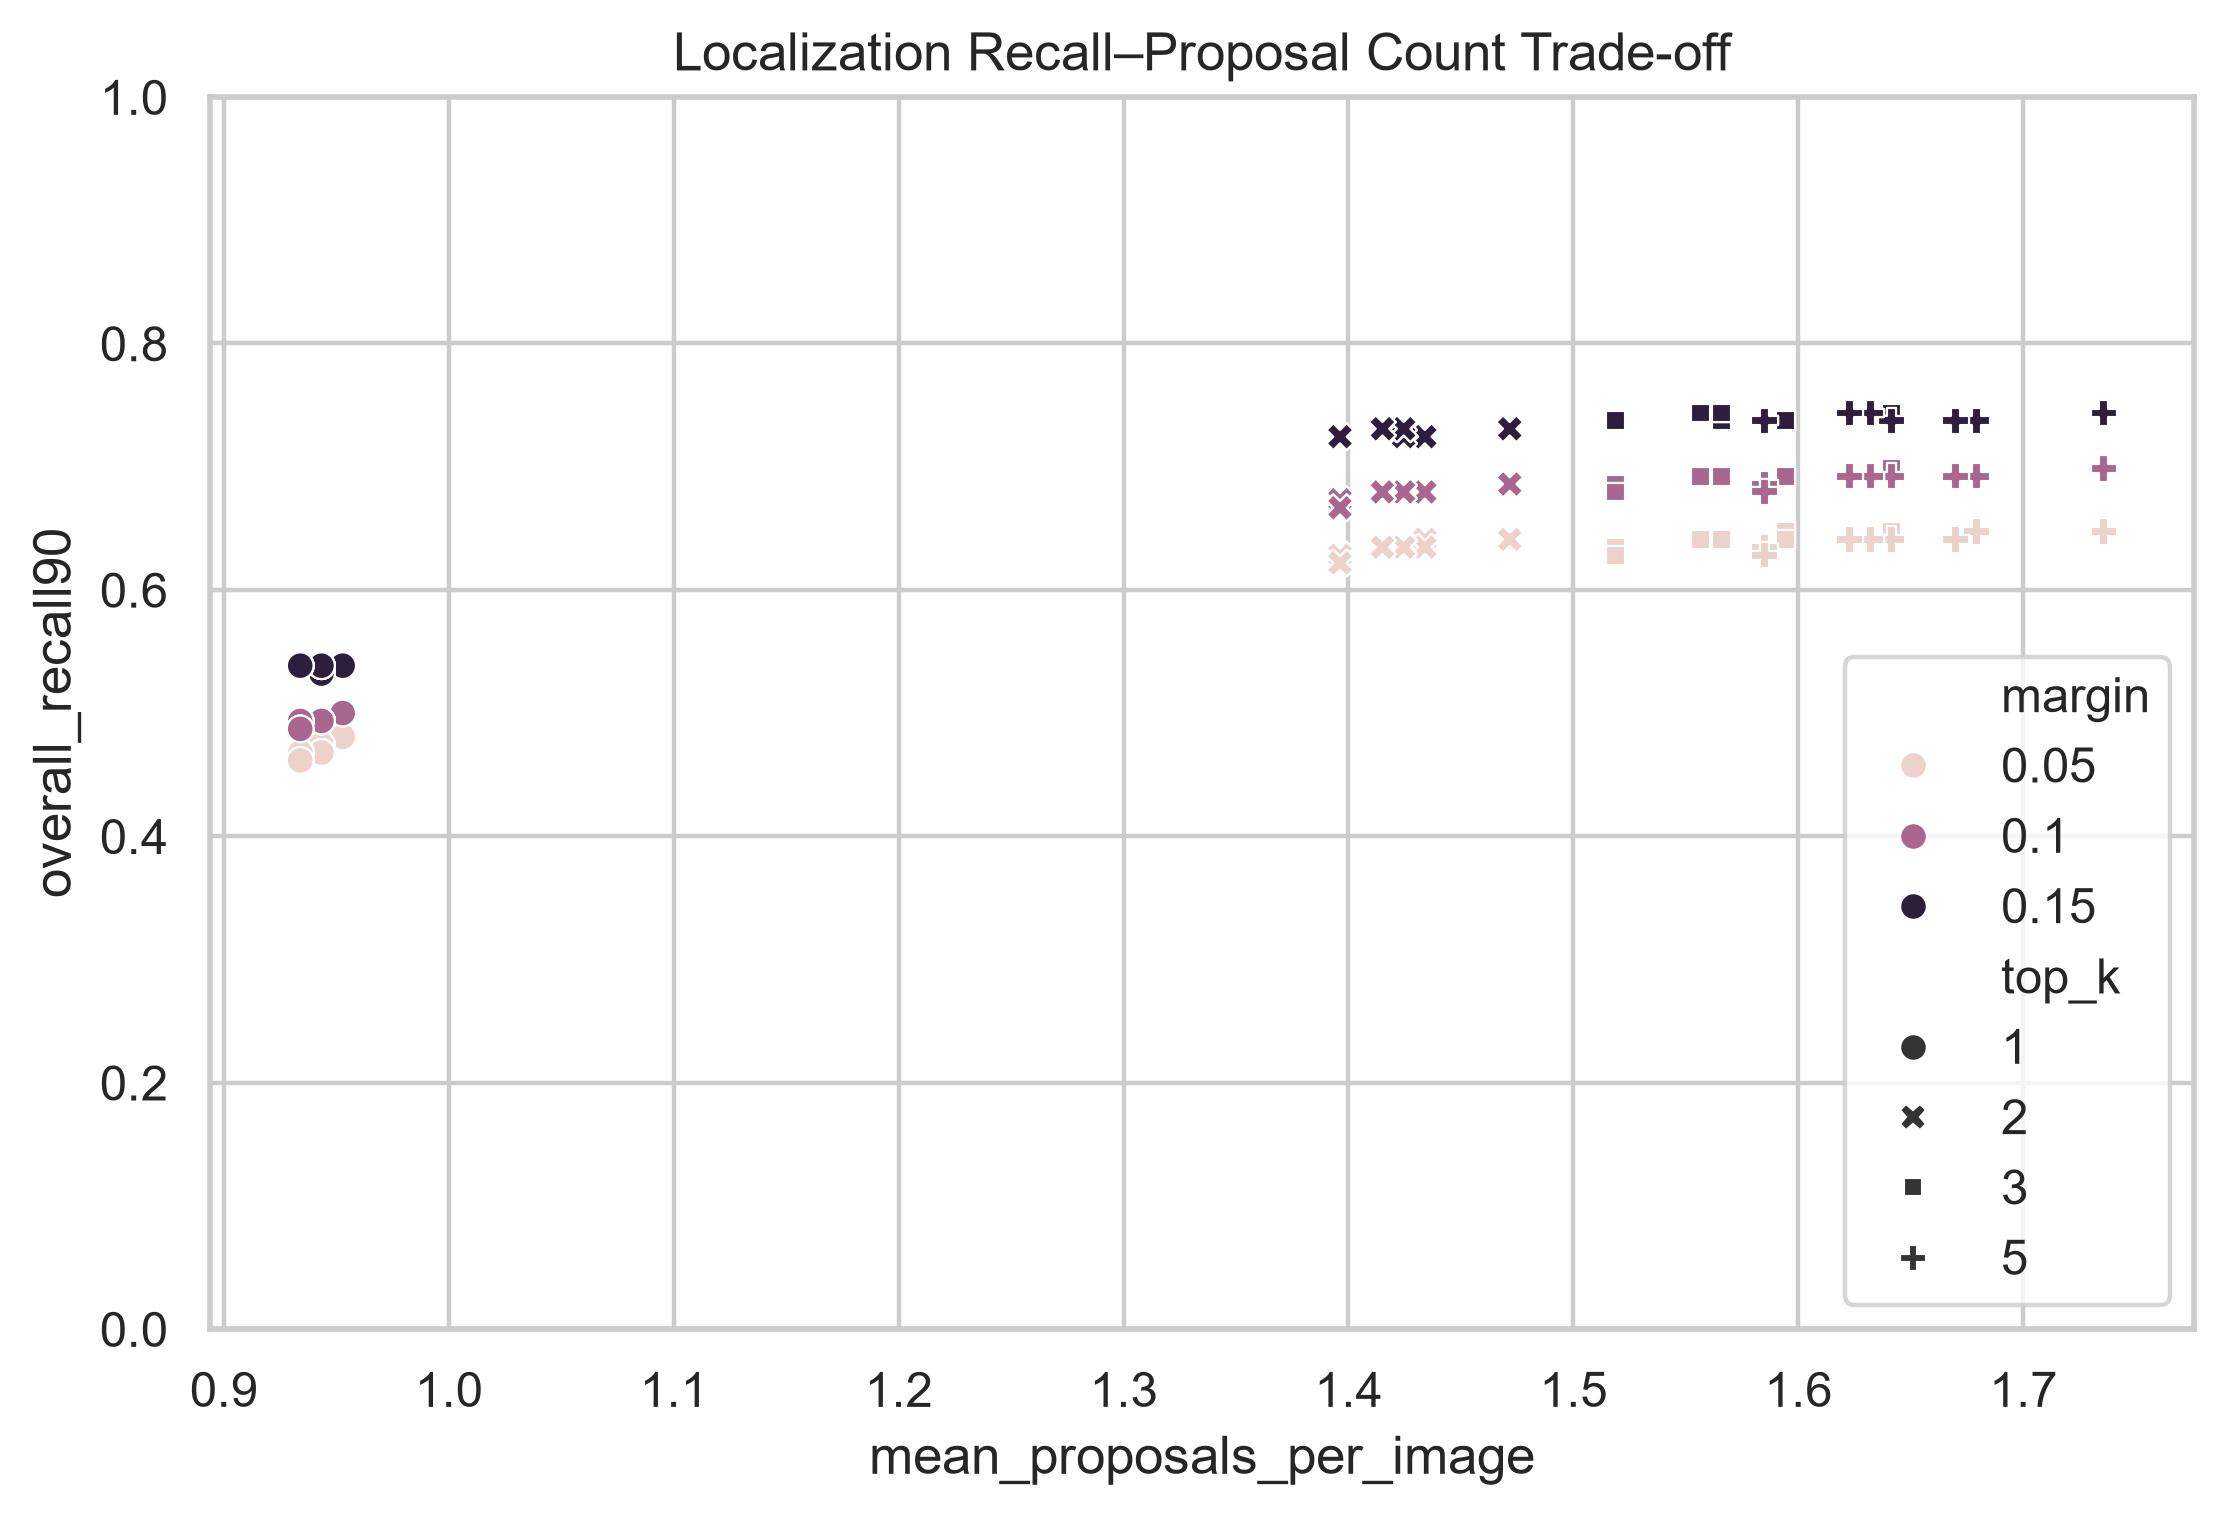

In [3]:
display(Image(filename=str(F/'phase13_proposal_recall_vs_threshold.png'),width=800))
display(Image(filename=str(F/'phase13_tiny_recall_vs_threshold.png'),width=800))
display(Image(filename=str(F/'phase13_recall_vs_roi_area_tradeoff.png'),width=800))
display(Image(filename=str(F/'phase13_recall_vs_proposal_count.png'),width=800))

## Localization by original-space size and global misses

,Size,GT,covered90,missed,recall90,mean_coverage,global_segmentation_detected,global_misses_localized_by_predicted_roi
0,TINY,73,50,23,0.684932,0.730591,57,0
1,SMALL,29,25,4,0.862069,0.886233,25,1
2,MEDIUM,36,28,8,0.777778,0.849526,32,0
3,LARGE,18,13,5,0.722222,0.773818,17,0


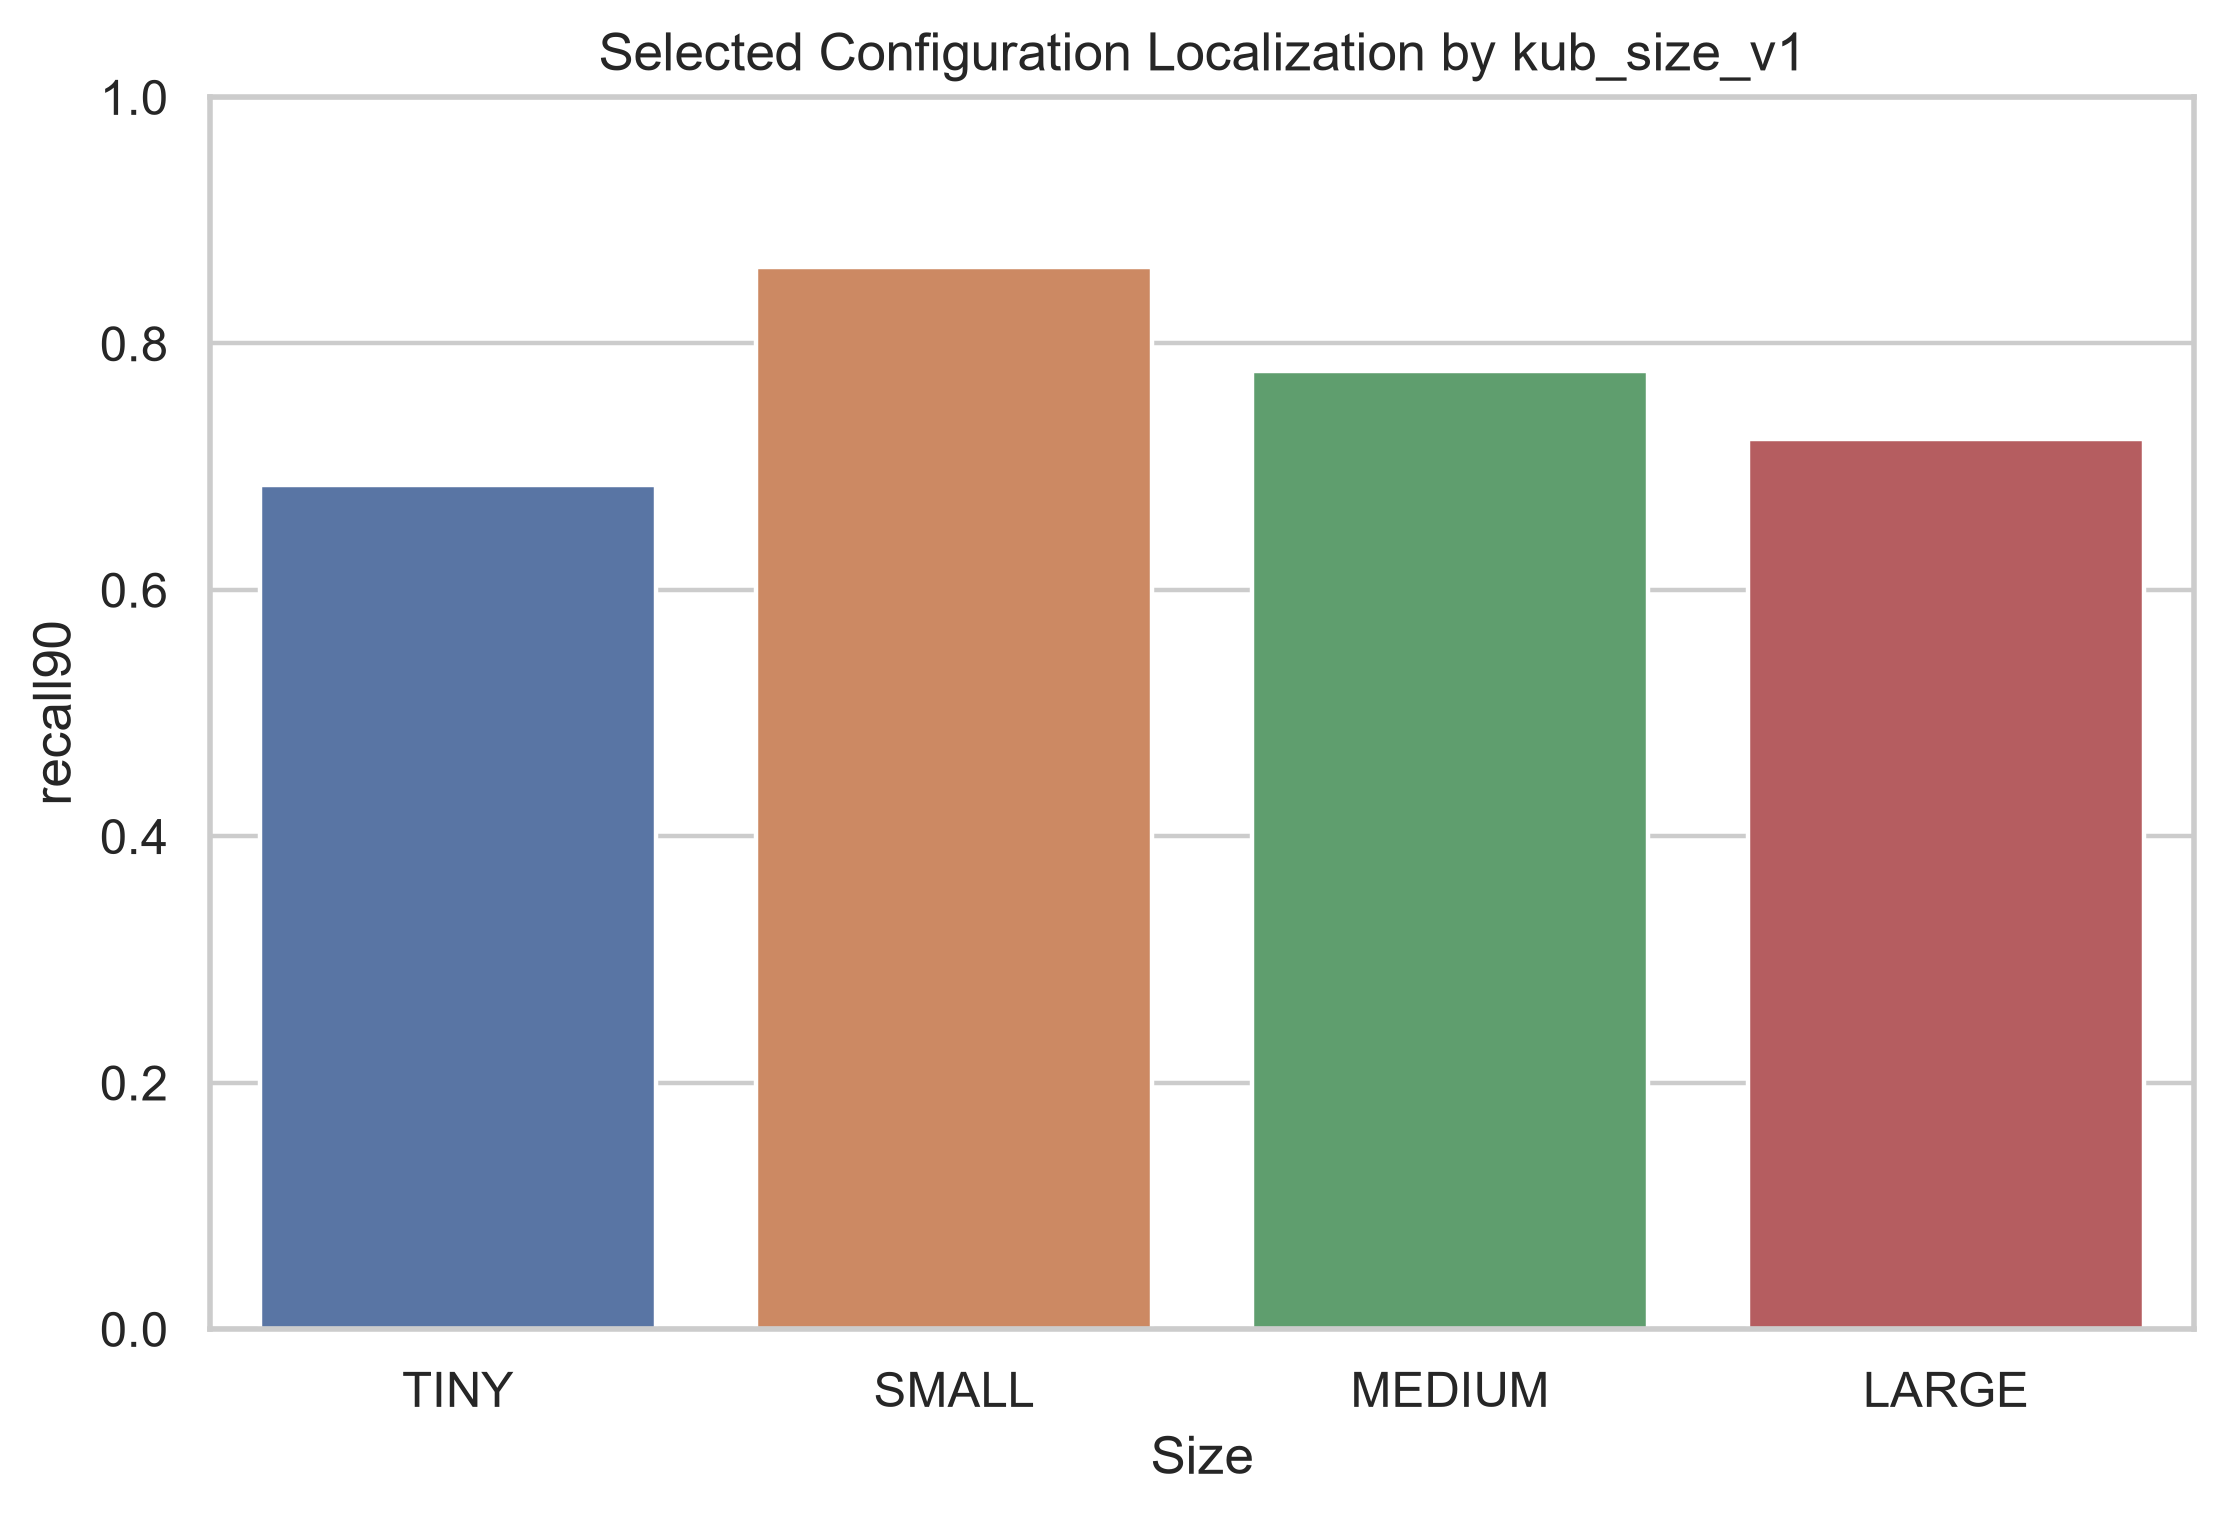

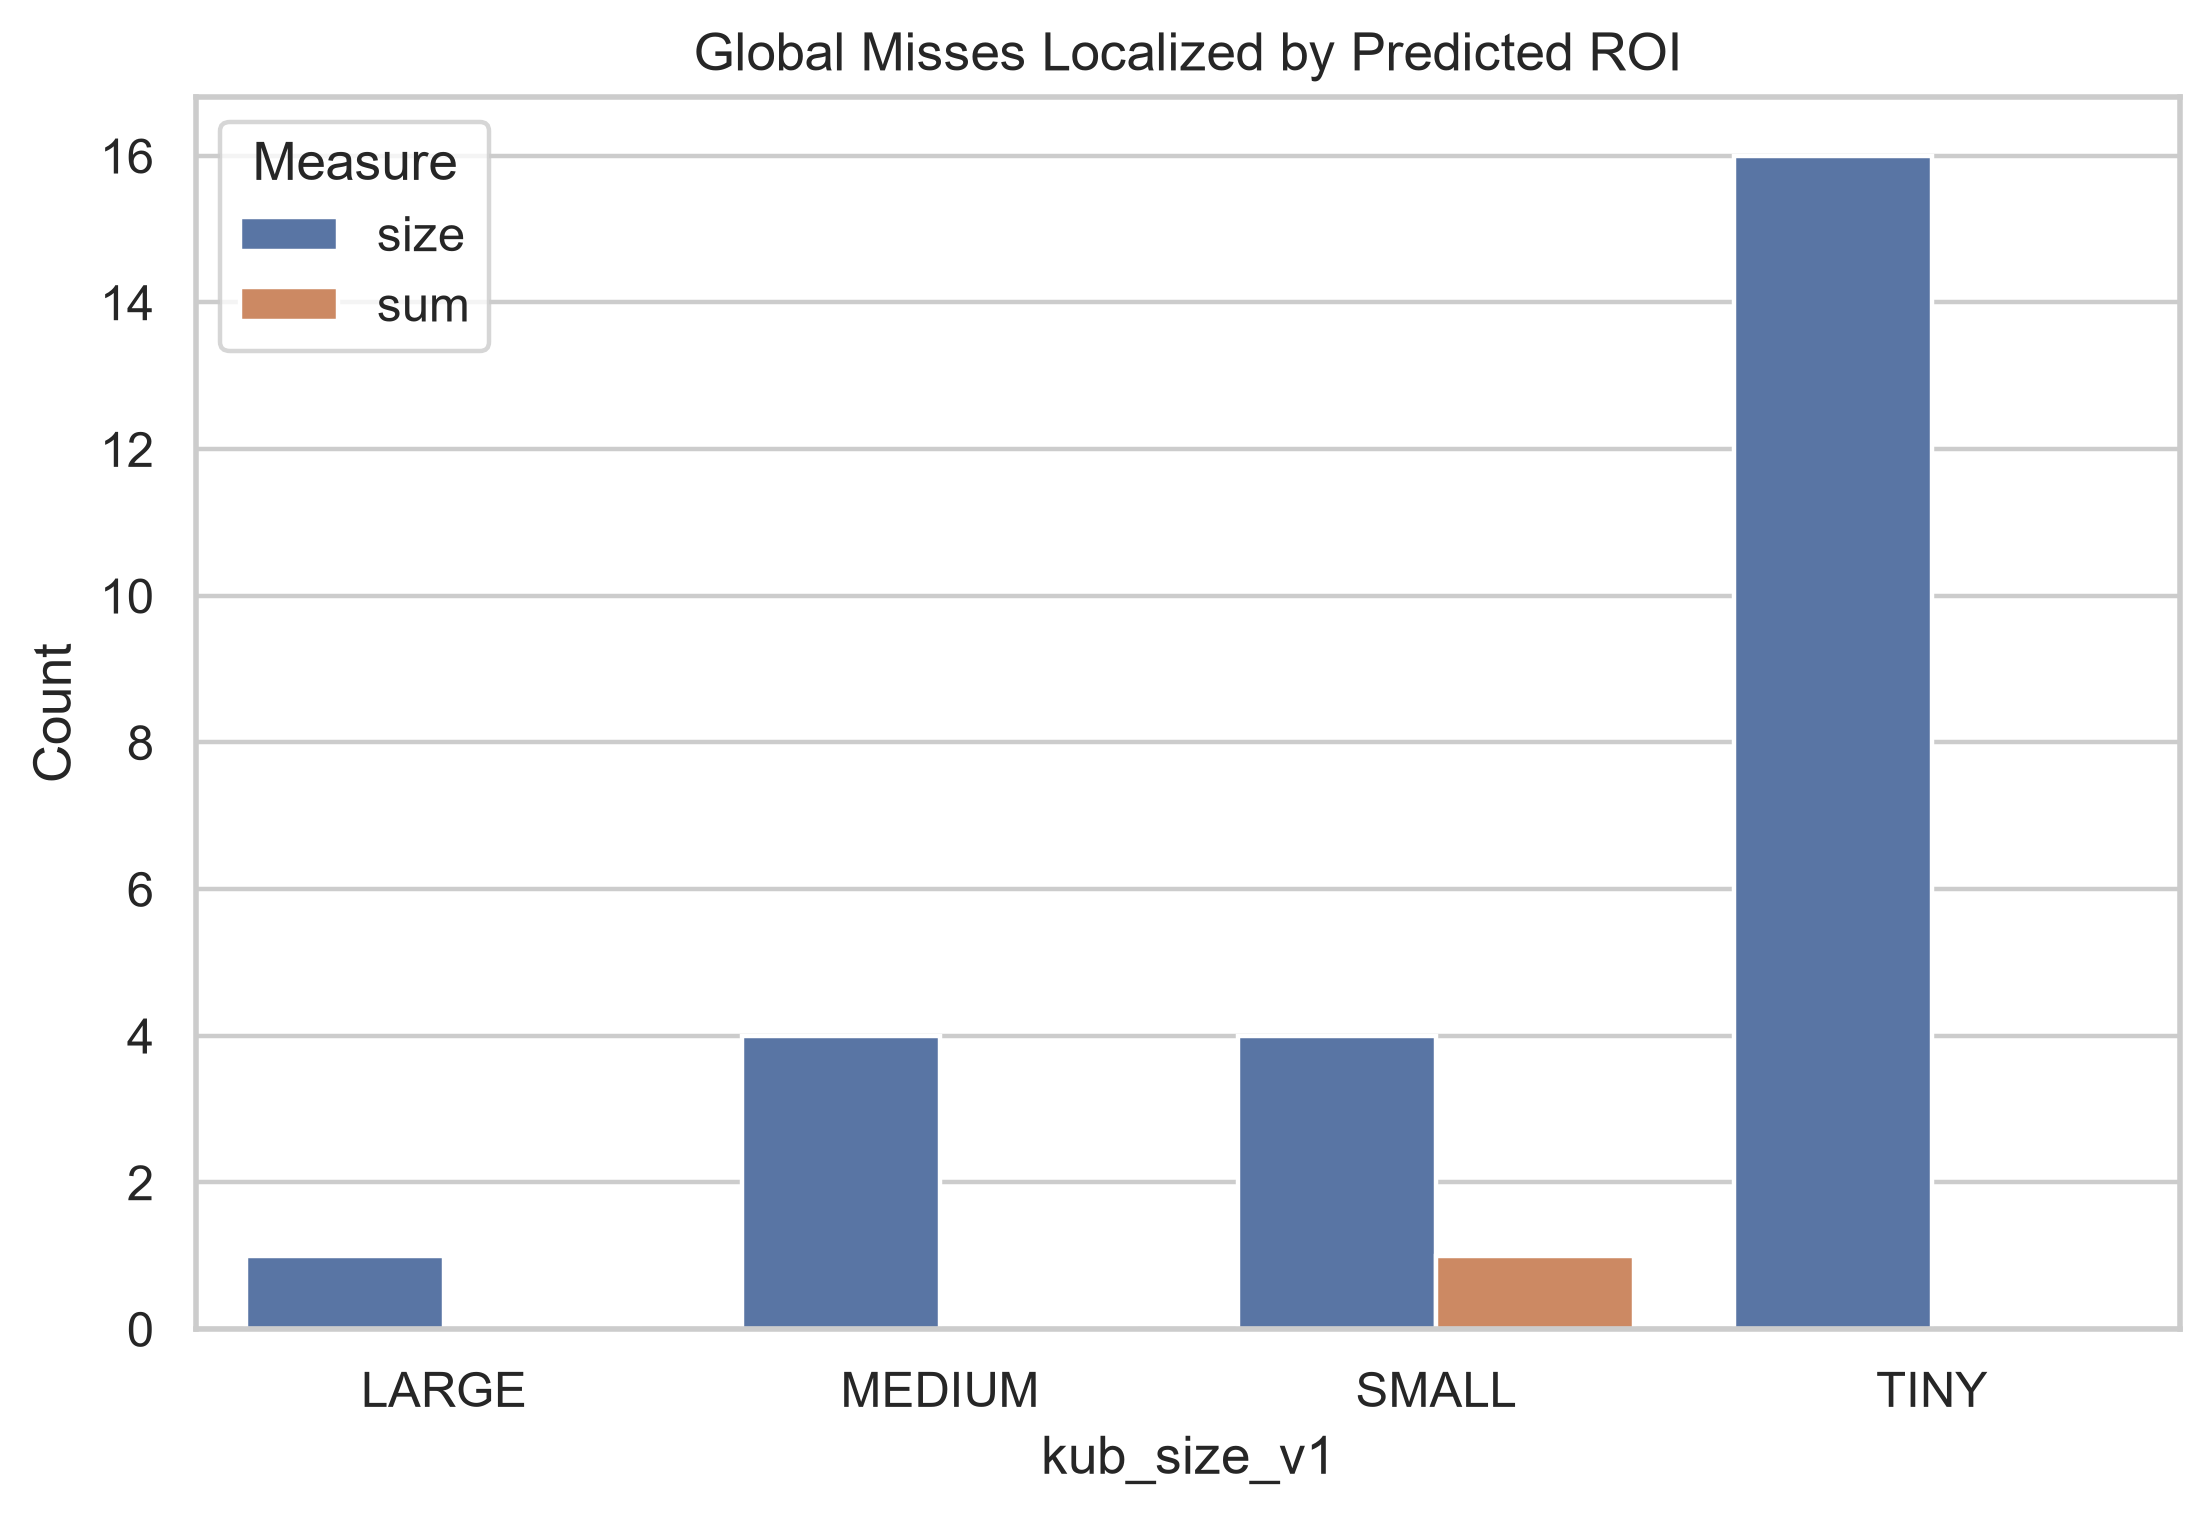

In [4]:
display(pd.read_csv(T/'phase13_predicted_roi_size_summary.csv'))
display(Image(filename=str(F/'phase13_size_stratum_localization.png'),width=800))
display(Image(filename=str(F/'phase13_global_miss_recovery_localization.png'),width=800))

## Empty global predictions and zero-proposal cases

In [5]:
display(pd.read_csv(T/'phase13_global_empty_case_analysis.csv'))
display(pd.read_csv(T/'phase13_zero_proposal_analysis.csv'))

,sample_id,patient_id,category,component_count_original,size_strata,coarse_max_probability,proposal_count,zero_proposal,components_covered90,global_empty_but_roi_found,max_coarse_probability_near_target
0,b0473630de9211114c94c7dc0363ebd9,patient-00053,Bladder_Stone,1,TINY,0.166626,0,True,0,False,0.166626
1,8c8d2107815002b7913bd6a42f93b394,patient-00107,Bladder_Stone,2,TINY,0.000079,0,True,0,False,0.000002
2,ad4af1ce1b3dde6ad04fa095aacd92f5,patient-00113,Bladder_Stone,1,TINY,0.000104,0,True,0,False,0.000000
3,abe658fa57a12b1665a96d00beeffae0,patient-00115,Bladder_Stone,2,MEDIUM;SMALL,0.230957,0,True,0,False,0.230957
4,f860cbfe7c79e5772795a64bac5de7e7,patient-01207,Bladder_Stone,1,TINY,0.005138,0,True,0,False,0.000006
5,e1e165d69d6844c8a599786d865cdd21,patient-01714,Bladder_Stone,2,TINY,0.000989,0,True,0,False,0.000989
6,5dd4436a2065b8855ce1dfbed228bce7,patient-00570,Kidney_Stone,2,SMALL,0.480713,0,True,0,False,0.000007


,sample_id,patient_id,category,component_count_original,size_strata,coarse_max_probability
0,b0473630de9211114c94c7dc0363ebd9,patient-00053,Bladder_Stone,1,TINY,0.166626
1,8c8d2107815002b7913bd6a42f93b394,patient-00107,Bladder_Stone,2,TINY,0.000079
2,ad4af1ce1b3dde6ad04fa095aacd92f5,patient-00113,Bladder_Stone,1,TINY,0.000104
3,abe658fa57a12b1665a96d00beeffae0,patient-00115,Bladder_Stone,2,MEDIUM;SMALL,0.230957
4,f860cbfe7c79e5772795a64bac5de7e7,patient-01207,Bladder_Stone,1,TINY,0.005138
5,e1e165d69d6844c8a599786d865cdd21,patient-01714,Bladder_Stone,2,TINY,0.000989
6,5dd4436a2065b8855ce1dfbed228bce7,patient-00570,Kidney_Stone,2,SMALL,0.480713


## Multi-component localization

,image_count,component_count,all_localized_images,partial_localized_images,none_localized_images,component_recall90,mean_fraction_components_covered,mean_proposals_per_image,top_k_saturation_images
0,50,100,27,16,7,0.7,0.7,1.94,0


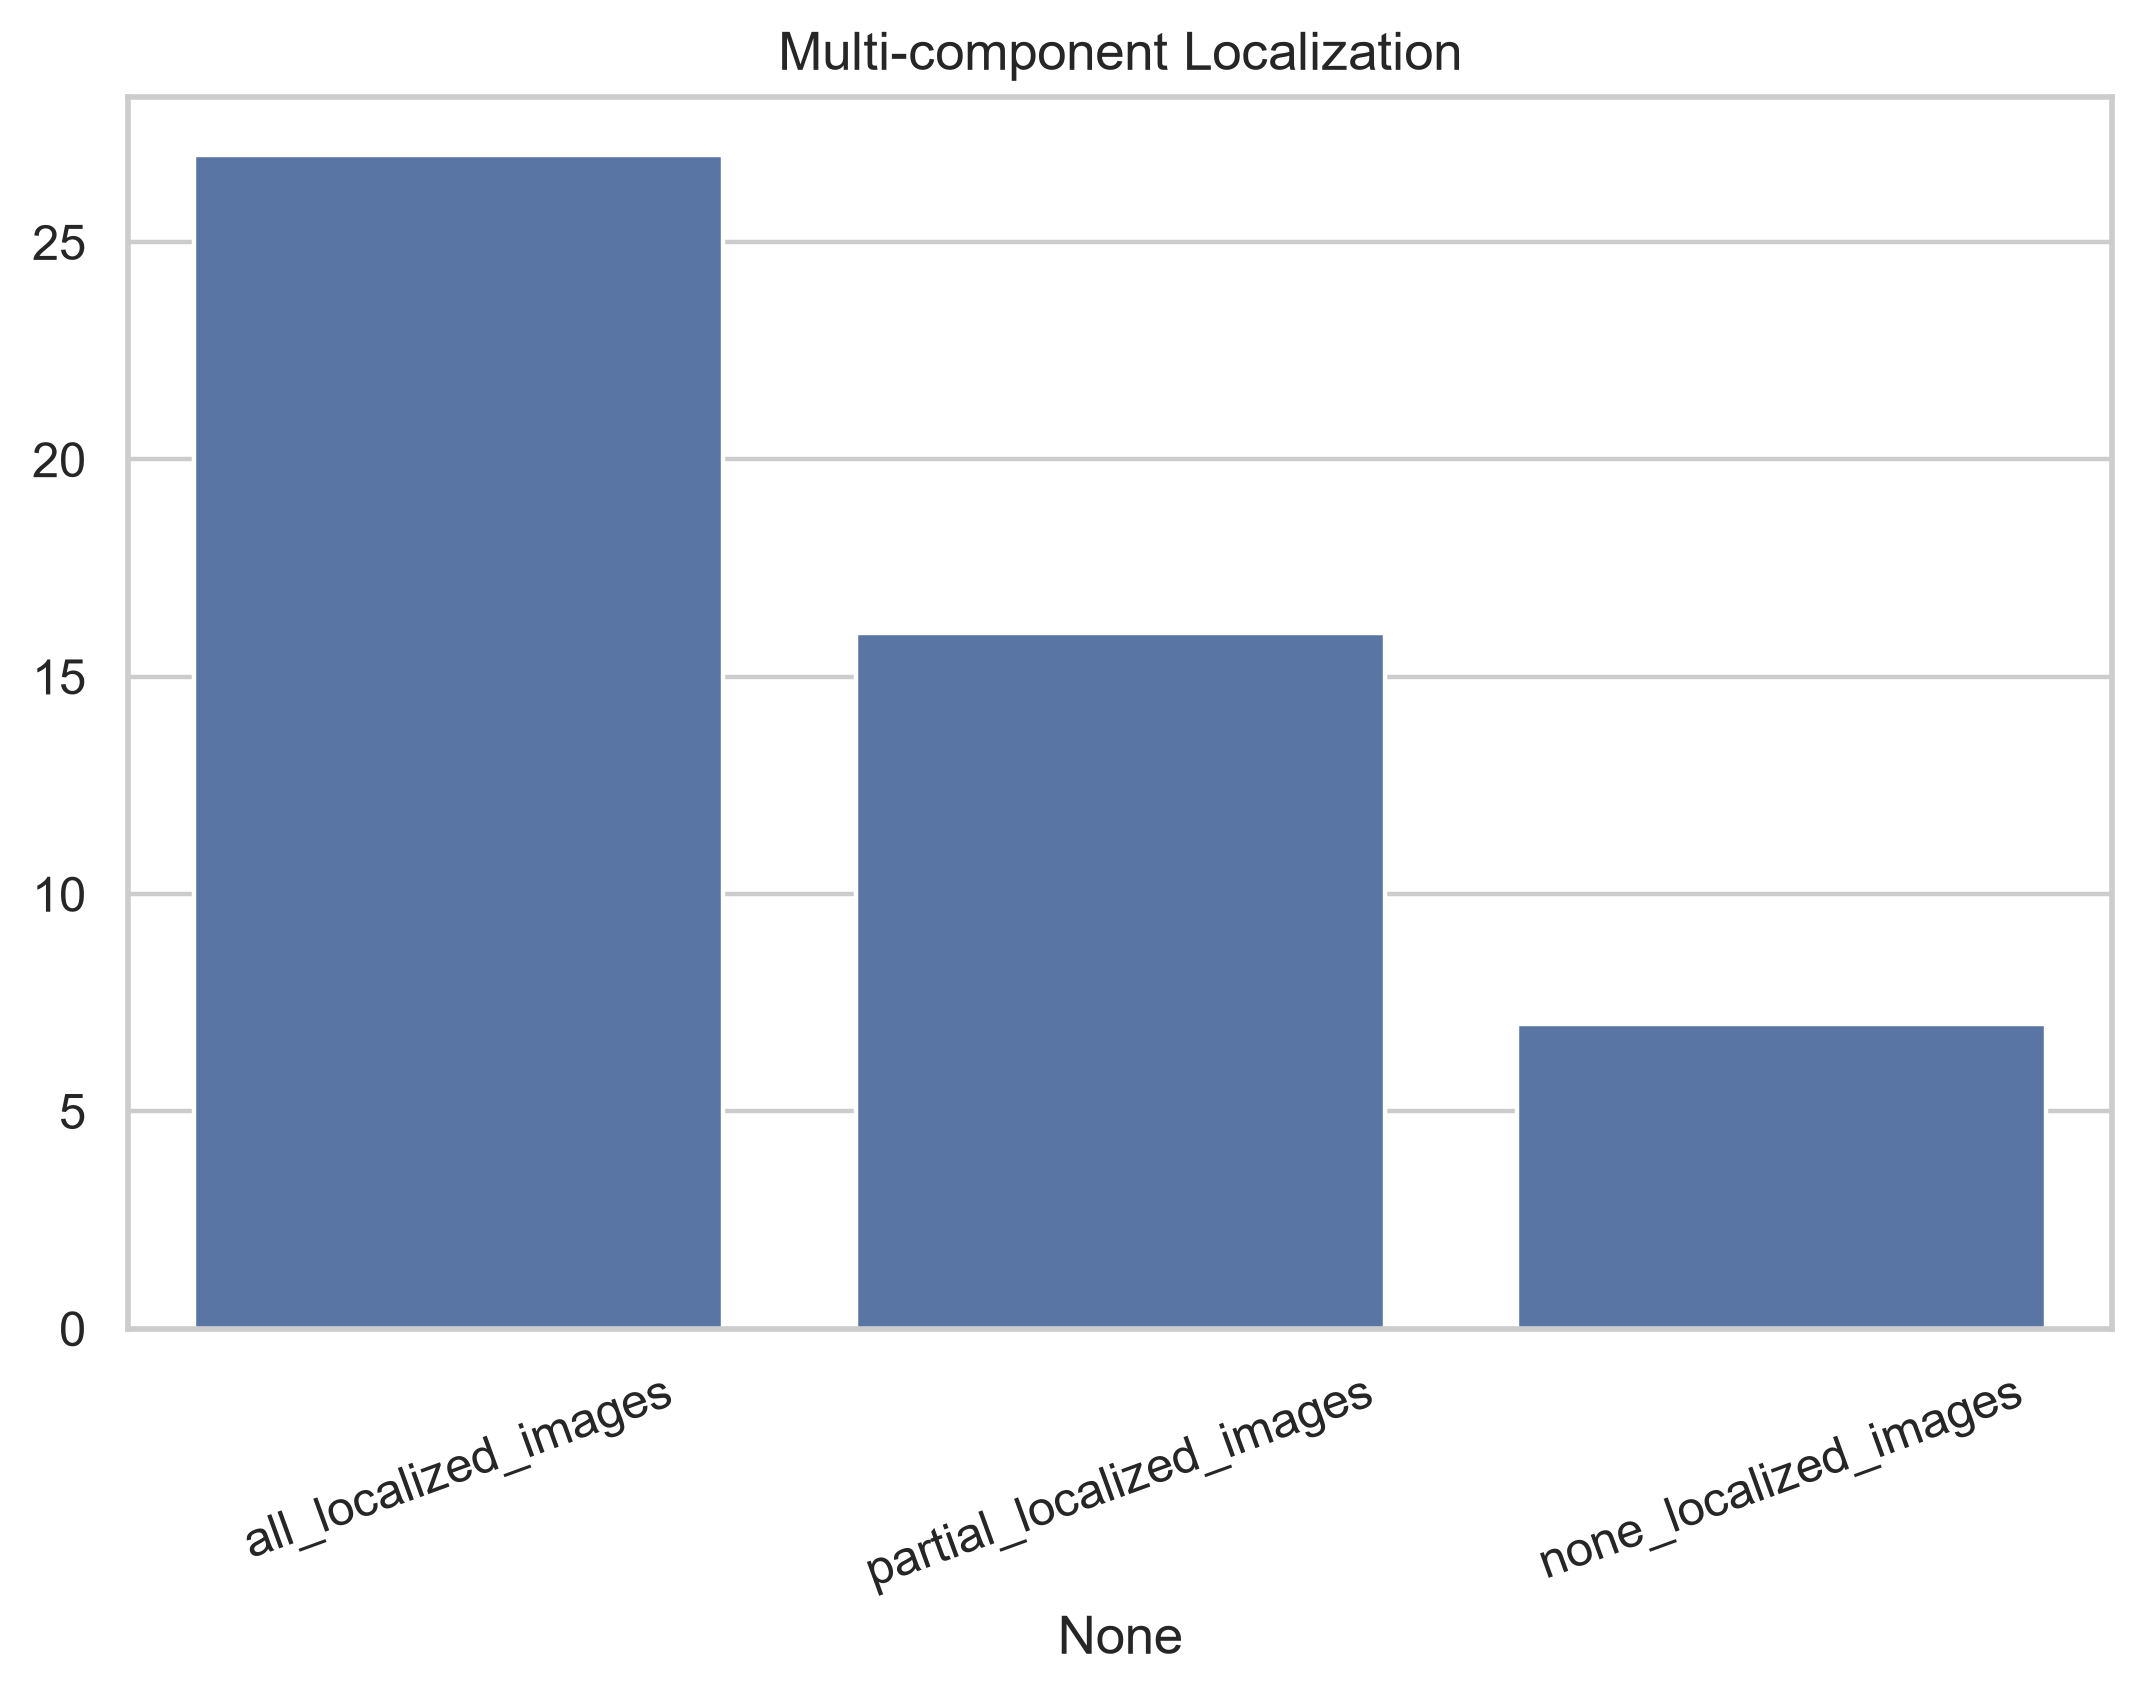

In [6]:
display(pd.read_csv(T/'phase13_predicted_roi_multicomponent.csv'))
display(Image(filename=str(F/'phase13_multicomponent_localization.png'),width=800))

## Search heatmap, coverage distribution, burden, and unmatched proposals

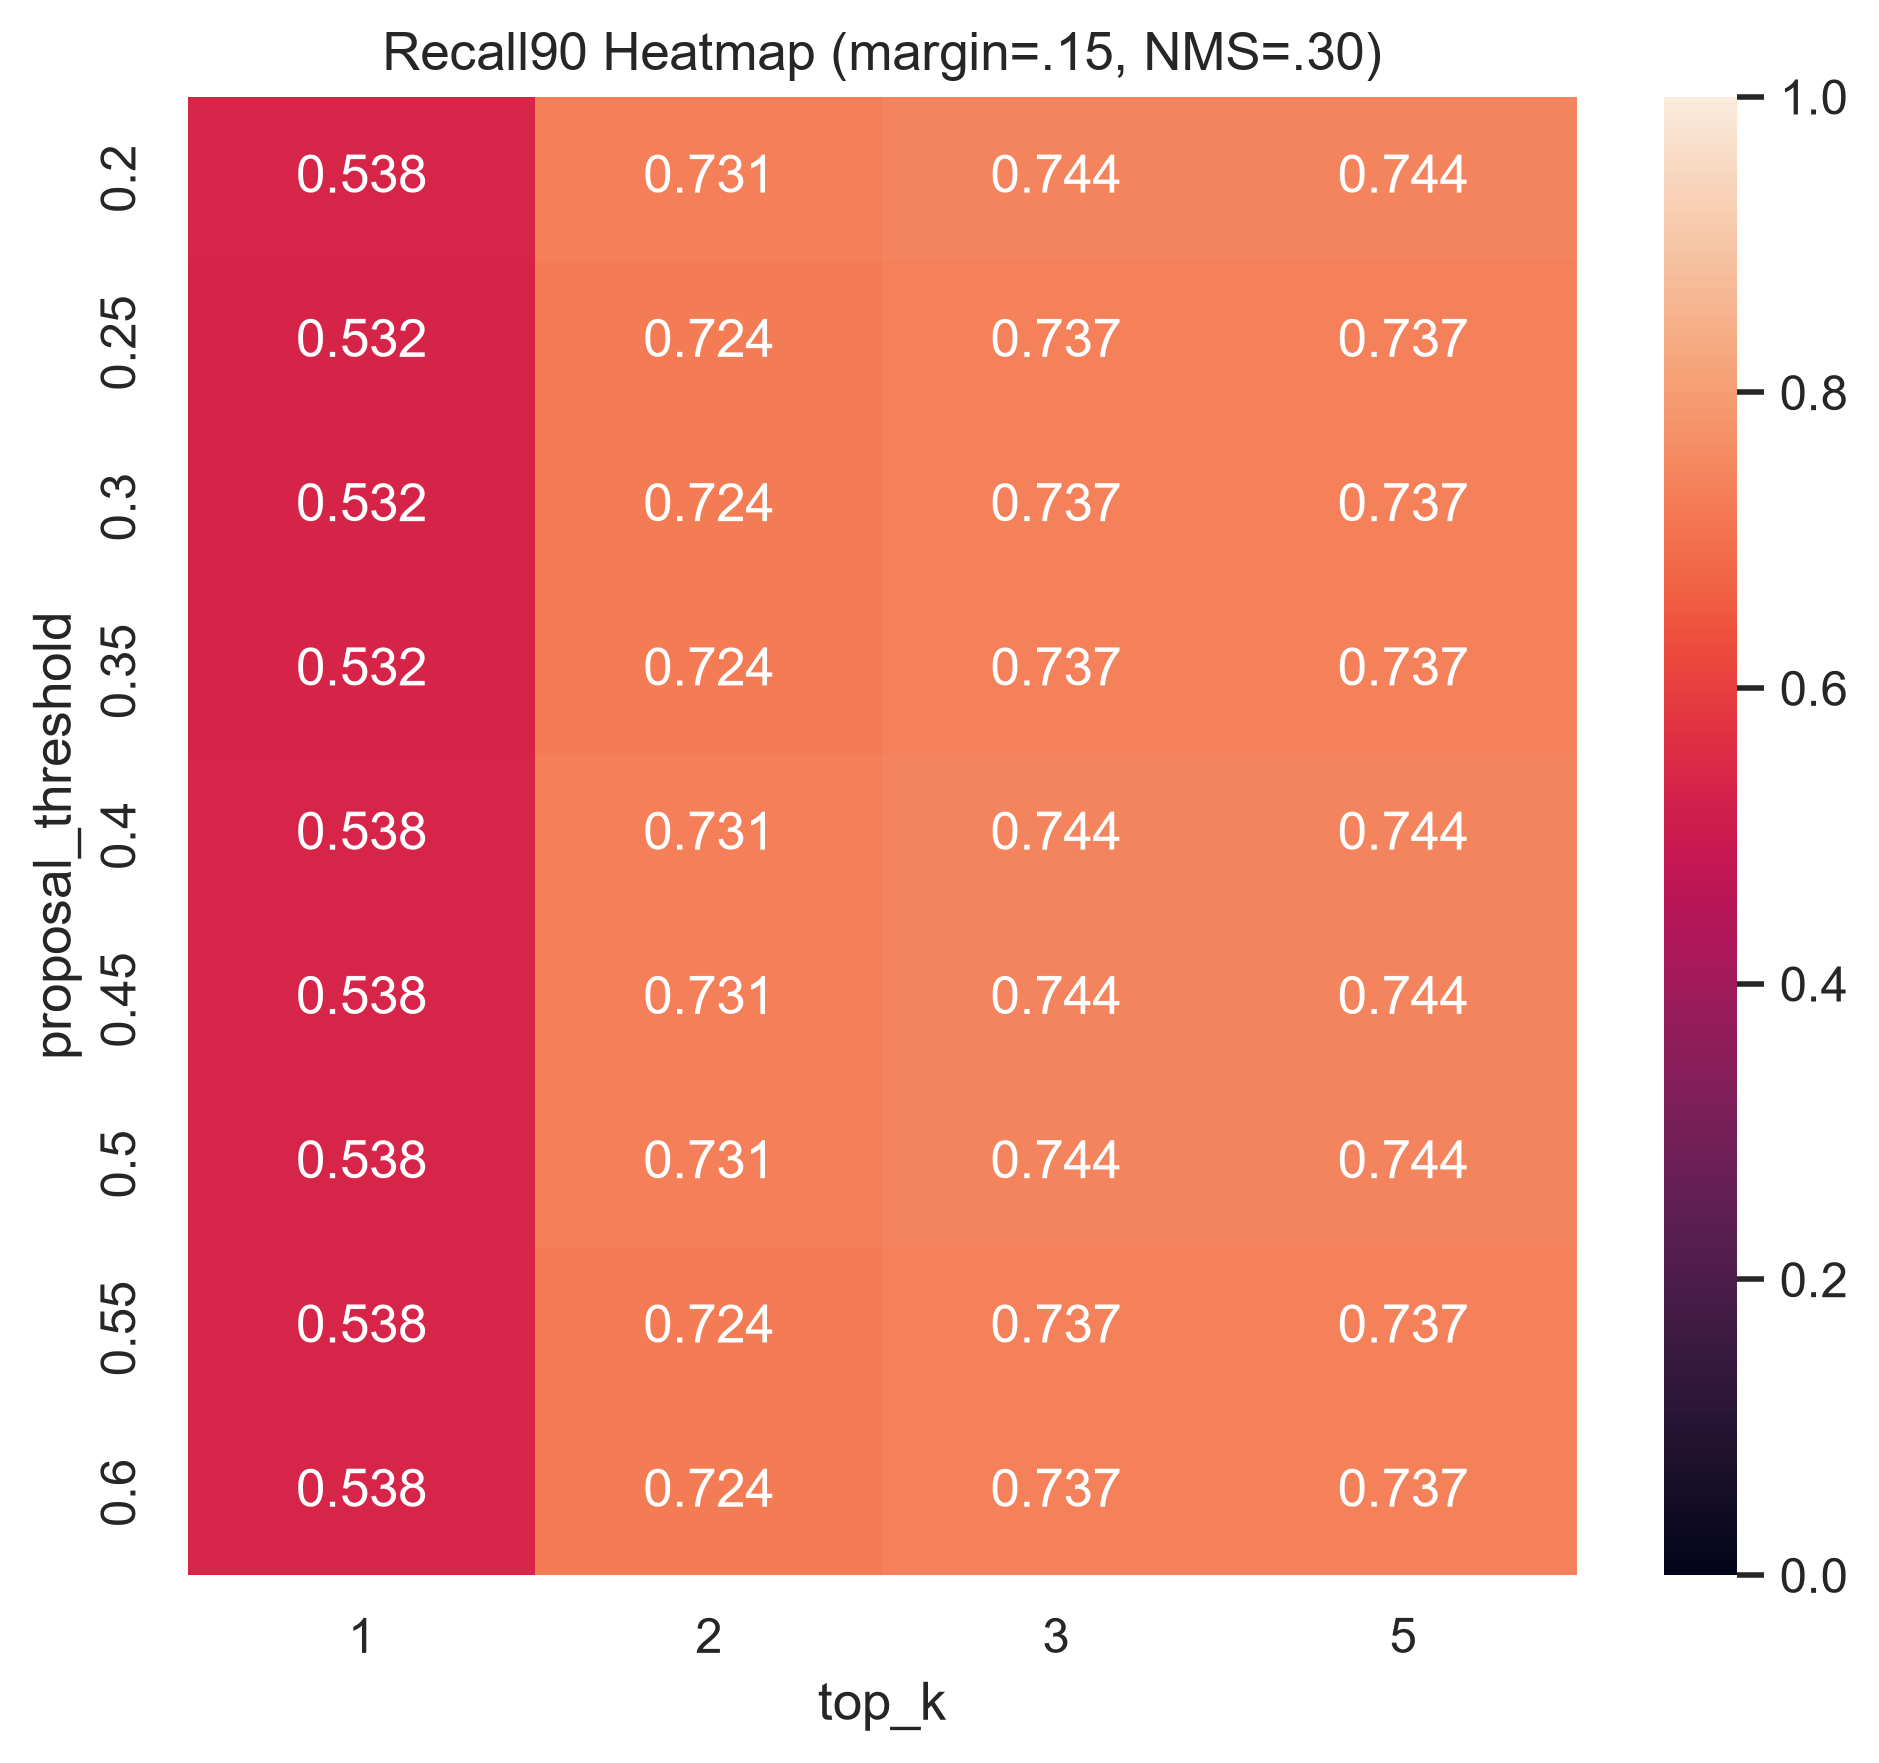

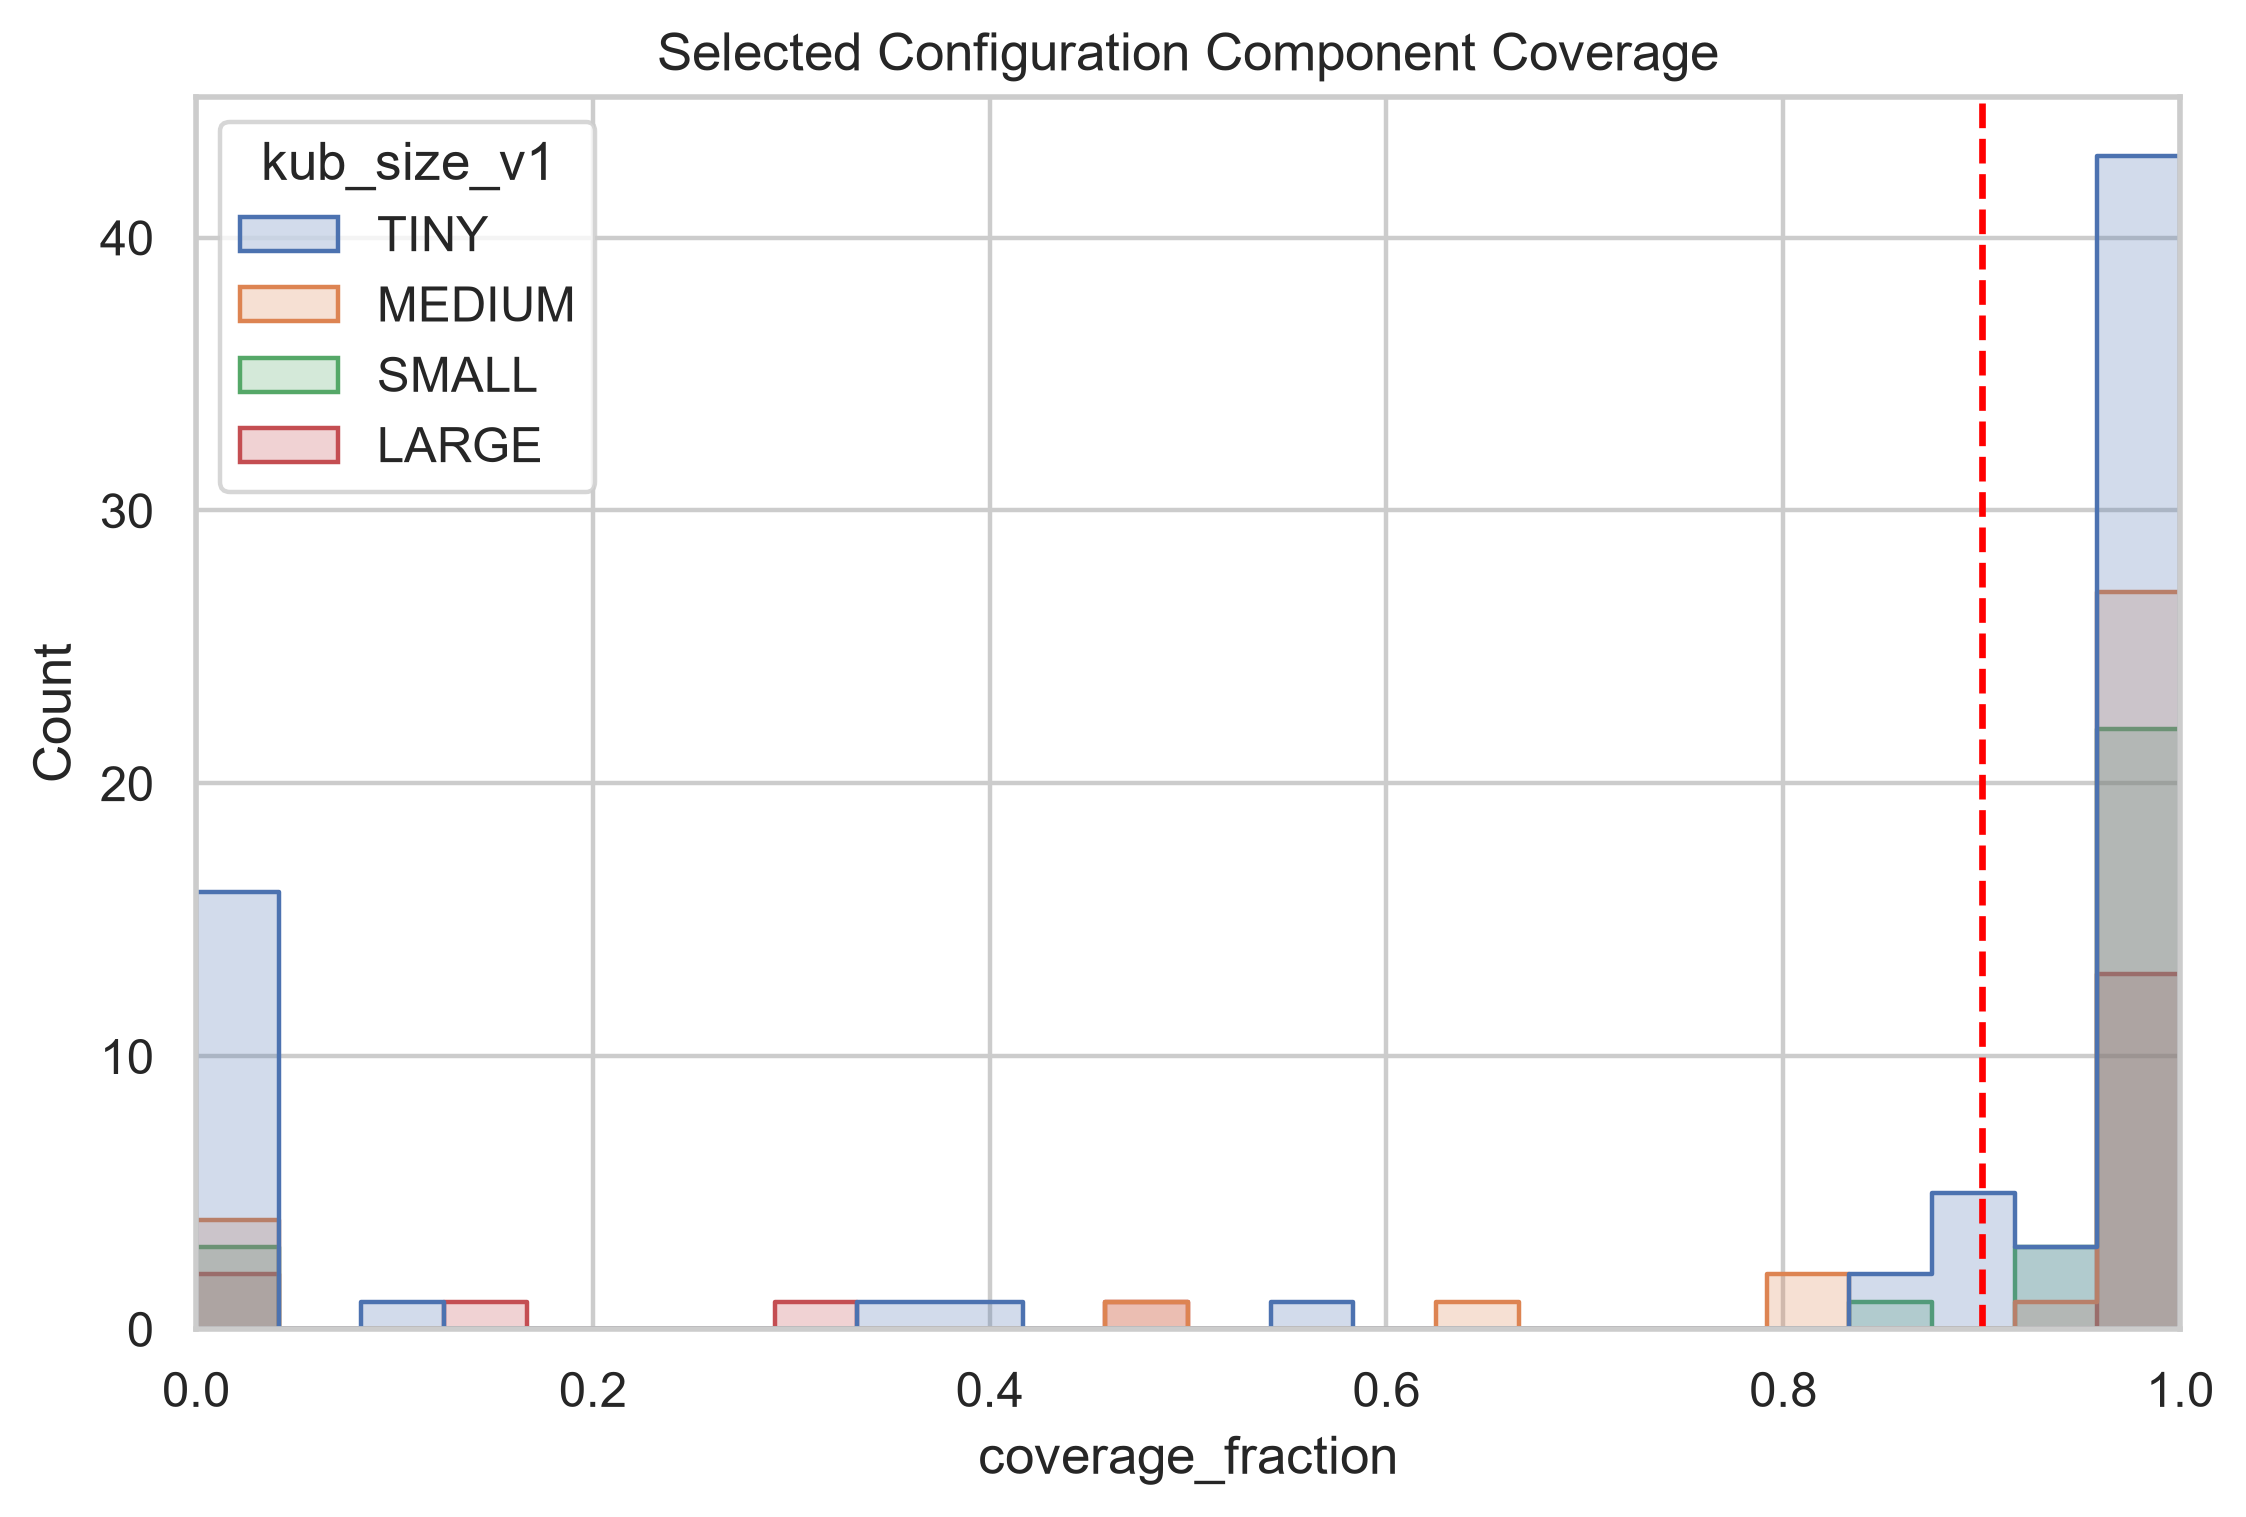

,proposal_count,total_roi_area_fraction,unmatched_proposals
count,106.000000,106.000000,106.000000
mean,1.556604,0.003091,0.339623
std,0.817431,0.012151,0.550096
min,0.000000,0.000000,0.000000
25%,1.000000,0.000224,0.000000
50%,1.000000,0.000634,0.000000
75%,2.000000,0.001796,1.000000
max,3.000000,0.117246,2.000000


In [7]:
display(Image(filename=str(F/'phase13_proposal_parameter_heatmap.png'),width=750))
display(Image(filename=str(F/'phase13_component_coverage_distribution.png'),width=800))
display(images[['proposal_count','total_roi_area_fraction','unmatched_proposals','zero_proposal']].describe())

## Deterministic qualitative panel

Red boxes are **PREDICTED** from coarse probability only. Green contours are **GT EVALUATION ONLY** and were not used to generate proposals.

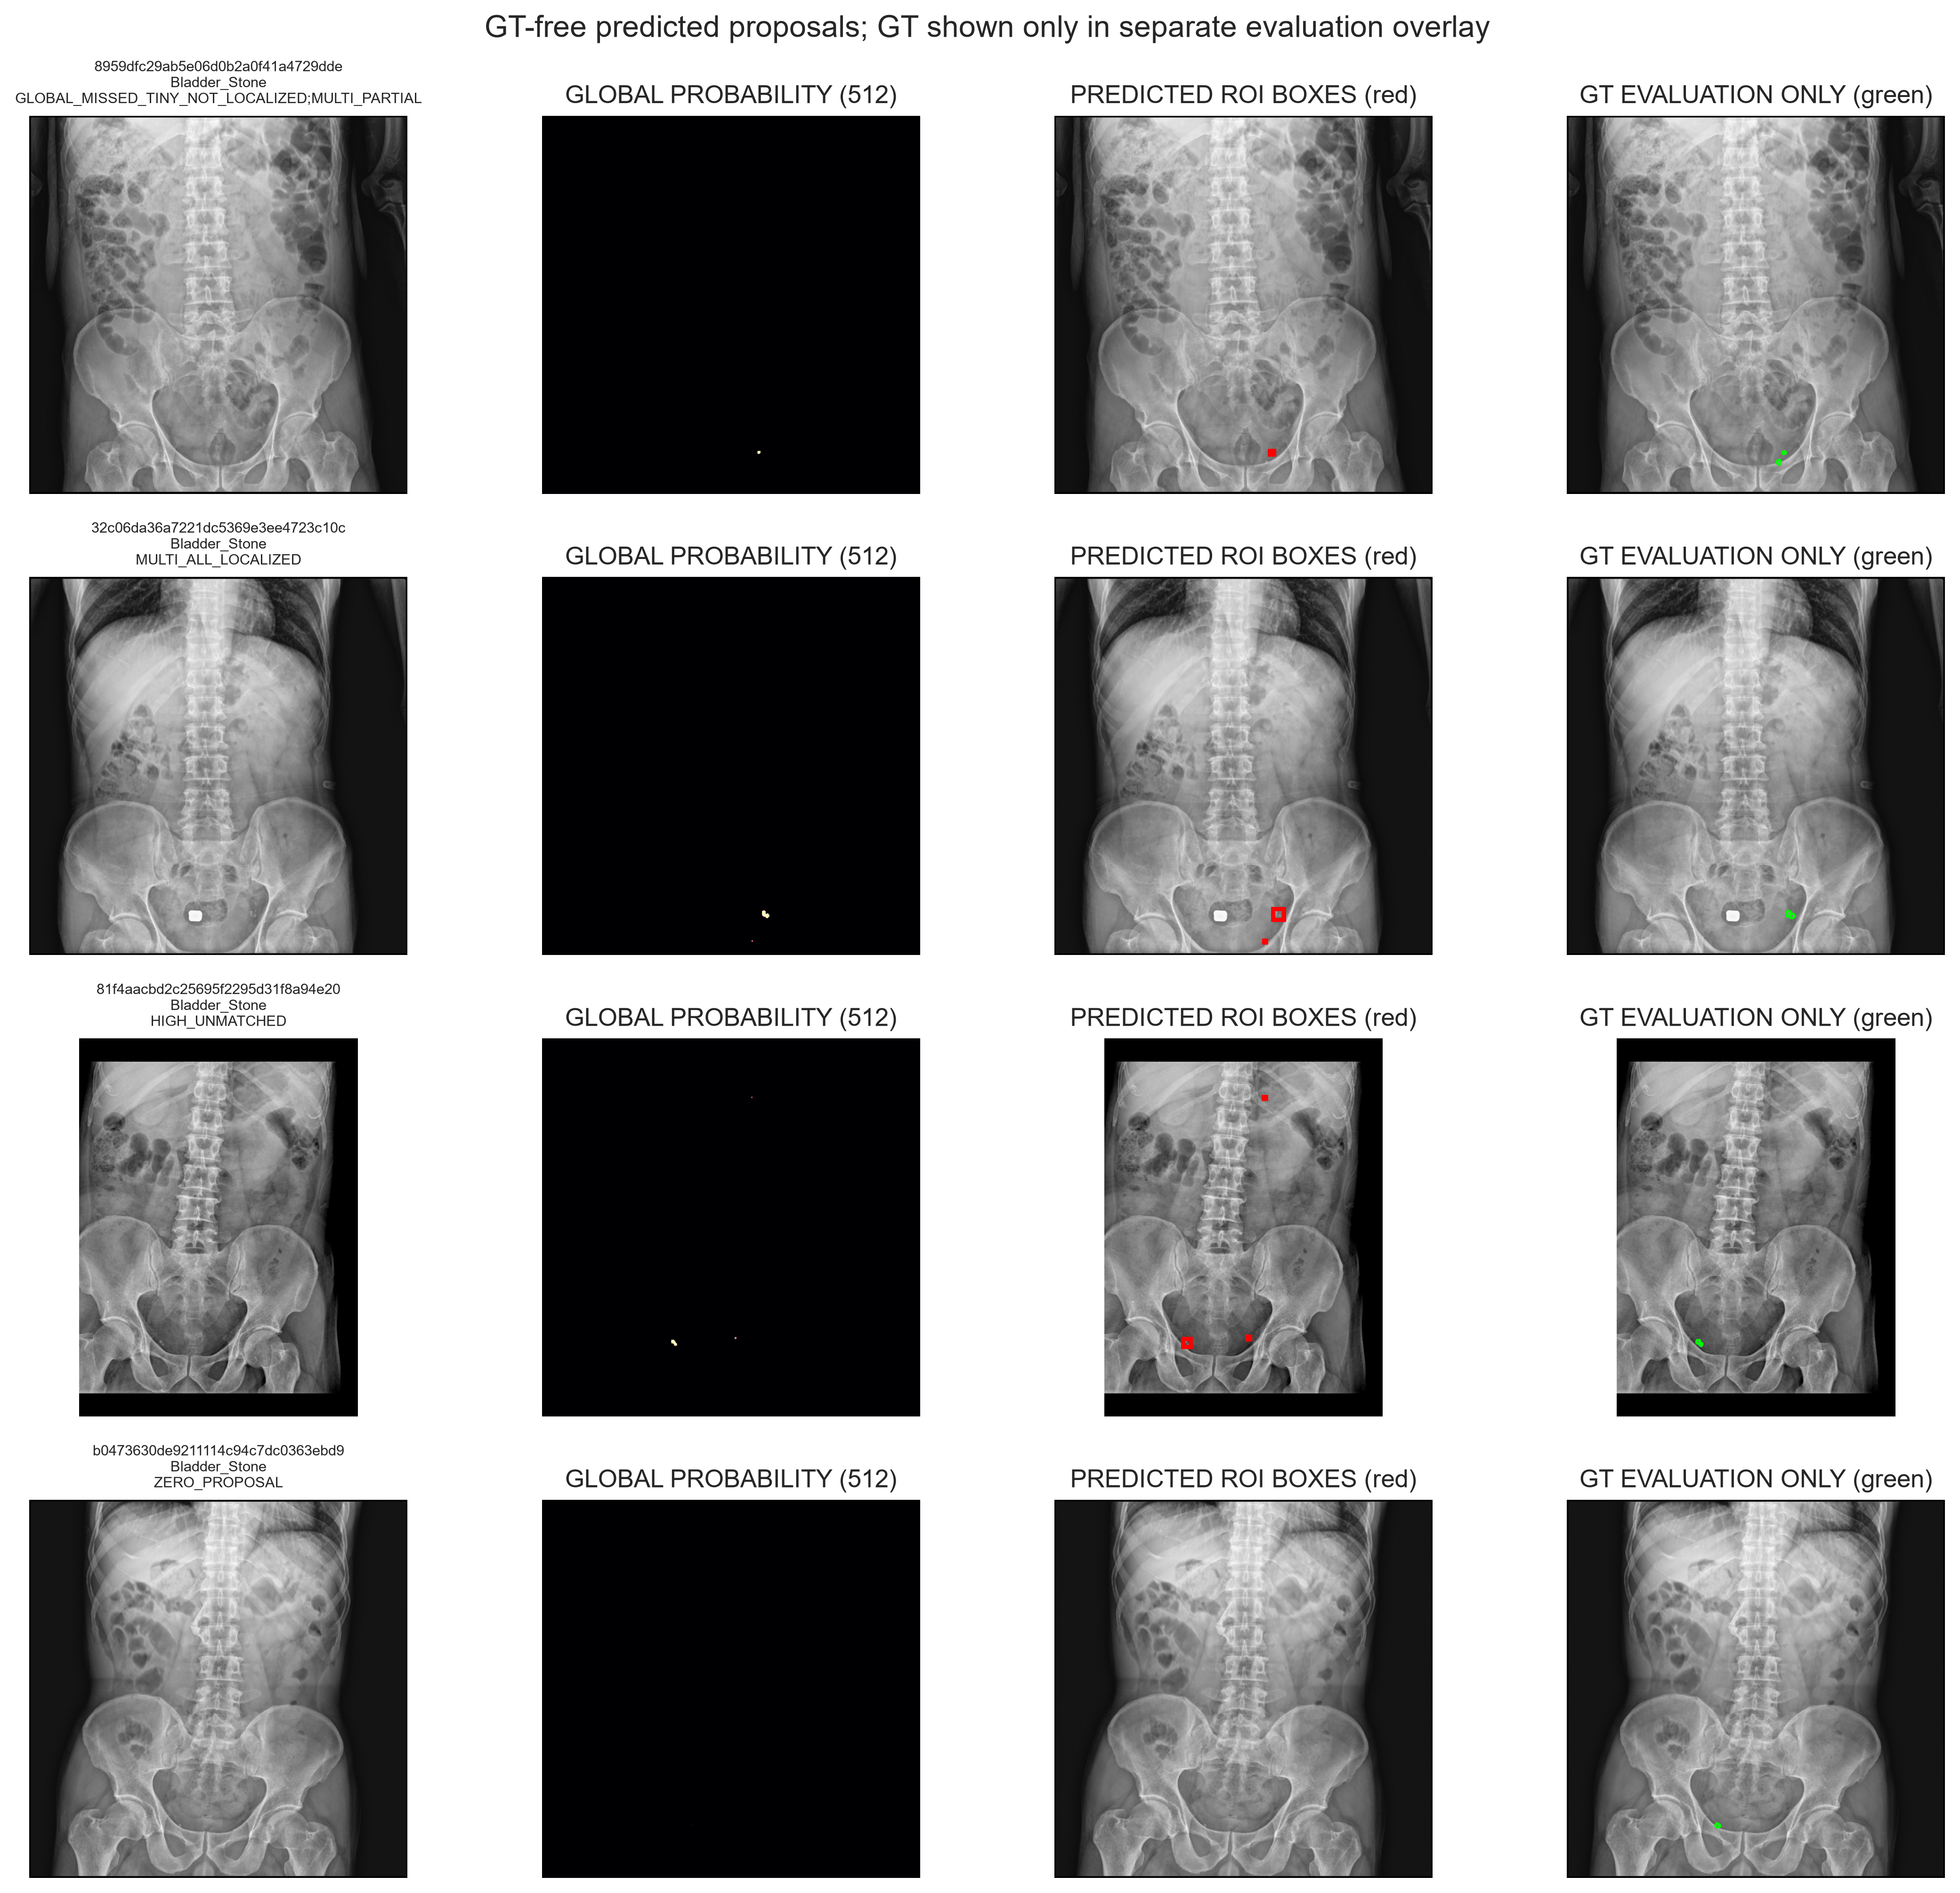

In [8]:
display(Image(filename=str(Q/'phase13_predicted_roi_localization_panel.png'),width=1300))

## Phase-14 gate and limitations

**Gate: WEAK.** Overall coverage recall is moderate with very low ROI-area burden, but the selected configuration localizes none of the 16 globally missed TINY components and none of the seven global-empty cases. A regional refiner trained only on these proposals would not access the key Oracle TINY headroom. A separately authorized stronger learned-localizer study should be considered before regional-refiner training. This is single-VAL descriptive development; no final segmentation superiority is claimed. **Phase 14 not executed. TEST NOT ACCESSED. STOP.**